# REGIONAL SALES PULSE
## Python Data Analysis Notebook

This notebook analyzes the Sample Superstore dataset. The original analysis code, tables, chart outputs, and dashboard are retained and organized into six analytical objectives. English explanations are added above the code cells, followed by interpretation and results for each objective.

**Dataset note:** Keep `Sample - Superstore.csv` in the same folder as this notebook before running it from top to bottom.

# Data Cleaning and Data Quality Assessment

This preliminary section loads the dataset, examines its structure and quality, checks missing and duplicate values, converts date fields, reviews numeric columns, and validates basic sales, quantity, and discount values. It is a preparation section and is not numbered as an objective.

**What this code does:** Imports pandas for reading and analyzing tabular data.

In [1]:
import pandas as pd

**What this code does:** Loads the original Sample Superstore CSV file into a DataFrame.

In [2]:
df = pd.read_csv("Sample - Superstore.csv",encoding="latin1")

**What this code does:** Displays the first five records to inspect the dataset.

In [3]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Unnamed: 21,Unnamed: 22,Unnamed: 23
0,1,CA-2016-152156,08-11-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,NaN,NaN,NaN
1,2,CA-2016-152156,08-11-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,NaN,NaN,NaN
2,3,CA-2016-138688,12-06-2016,16-06-2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,NaN,NaN,NaN
3,4,US-2015-108966,11-10-2015,18-10-2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,NaN,NaN,NaN
4,5,US-2015-108966,11-10-2015,18-10-2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,NaN,NaN,NaN


**What this code does:** Checks the number of rows and columns in the dataset.

In [4]:
df.shape

(9994, 24)

**What this code does:** Displays all column names.

In [5]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit',
       'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23'],
      dtype='str')

**What this code does:** Displays column data types and non-null counts.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

**What this code does:** Counts missing values in each column.

In [7]:
df.isnull().sum()

Row ID              0
Order ID            0
Order Date          0
Ship Date           0
Ship Mode           0
Customer ID         0
Customer Name       0
Segment             0
Country             0
City                0
State               0
Postal Code         0
Region              0
Product ID          0
Category            0
Sub-Category        0
Product Name        0
Sales               0
Quantity            0
Discount            0
Profit              0
Unnamed: 21      9994
Unnamed: 22      9994
Unnamed: 23      9992
dtype: int64

**What this code does:** Counts duplicate rows.

In [8]:
df.duplicated().sum()

np.int64(0)

**What this code does:** Creates a working copy so the original DataFrame remains unchanged.

In [9]:
df_clean =df.copy()

**What this code does:** Removes leading and trailing spaces from column names.

In [10]:
df_clean.columns =df_clean.columns.str.strip()

**What this code does:** Displays the cleaned column names.

In [11]:
df_clean.columns.tolist()

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit',
 'Unnamed: 21',
 'Unnamed: 22',
 'Unnamed: 23']

**What this code does:** Converts Order Date and Ship Date into datetime values; invalid dates become missing.

In [12]:
df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

df_clean["Ship Date"] = pd.to_datetime(
    df_clean["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

**What this code does:** Rechecks data types after date conversion.

In [13]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

**What this code does:** Checks missing values after date conversion.

In [14]:
df_clean.isnull().sum()

Row ID              0
Order ID            0
Order Date          0
Ship Date           0
Ship Mode           0
Customer ID         0
Customer Name       0
Segment             0
Country             0
City                0
State               0
Postal Code         0
Region              0
Product ID          0
Category            0
Sub-Category        0
Product Name        0
Sales               0
Quantity            0
Discount            0
Profit              0
Unnamed: 21      9994
Unnamed: 22      9994
Unnamed: 23      9992
dtype: int64

**What this code does:** Checks the data type of the Sales column.

In [15]:
df_clean["Sales"].dtype

dtype('float64')

**What this code does:** Displays Sales, Quantity, Discount, and Profit values for inspection.

In [16]:
df_clean[["Sales","Quantity","Discount","Profit"]]

,Sales,Quantity,Discount,Profit
0,261.9600,2,0.00,41.9136
1,731.9400,3,0.00,219.5820
2,14.6200,2,0.00,6.8714
3,957.5775,5,0.45,-383.0310
4,22.3680,2,0.20,2.5164
...,...,...,...,...
9989,25.2480,3,0.20,4.1028
9990,91.9600,2,0.00,15.6332
9991,258.5760,2,0.20,19.3932
9992,29.6000,4,0.00,13.3200


**What this code does:** Produces descriptive statistics for the main numeric fields.

In [17]:
df_clean[["Sales","Quantity","Discount","Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


**What this code does:** Counts records with zero or negative sales.

In [18]:
df_clean[df_clean["Sales"] <= 0].shape[0]

0

**What this code does:** Counts records with zero or negative quantity.

In [19]:
df_clean[df_clean["Quantity"] <= 0].shape[0]

0

**What this code does:** Counts records with discounts outside the valid 0-to-1 range.

In [20]:
df_clean[
    (df_clean["Discount"] < 0) |
    (df_clean["Discount"] > 1)
].shape[0]

0

**What this code does:** Checks the earliest and latest order dates in the dataset.

In [21]:
df_clean["Order Date"].min(), df_clean["Order Date"].max()

(Timestamp('2014-01-03 00:00:00'), Timestamp('2017-12-30 00:00:00'))

### Interpretation and Results

The supplied dataset contains **9,994 rows** and **21 columns**, representing **5,009 unique orders**. The order-date coverage is **02 Jan 2014 to 11 Dec 2017**. The original notebook's validation outputs report no records with non-positive Sales, no records with non-positive Quantity, and no discounts outside the 0-to-1 range. The missing-value and duplicate checks remain available above for review.

# Objective 1: Loss-Making Orders and Product Profitability Analysis

This objective identifies orders with negative profit, examines the categories and sub-categories associated with losses, and compares loss-making records with overall sub-category profitability.

**What this code does:** Counts the records where Profit is negative.

In [22]:
df_clean[df_clean["Profit"]<0].shape[0]

1871

**What this code does:** Creates a DataFrame containing only loss-making records.

In [23]:
loss_data= df_clean[df_clean["Profit"]<0]

**What this code does:** Displays selected details for the first ten loss-making records.

In [24]:
loss_data[["Order ID", "Product Name", "Category", "Sub-Category", "Region", "Sales", "Discount", "Profit"]].head(10)

,Order ID,Product Name,Category,Sub-Category,Region,Sales,Discount,Profit
3,US-2015-108966,Bretford CR4500 Series Slim Rectangular Table,Furniture,Tables,South,957.5775,0.45,-383.0310
14,US-2015-118983,Holmes Replacement Filter for HEPA Air Cleaner...,Office Supplies,Appliances,Central,68.8100,0.80,-123.8580
15,US-2015-118983,Storex DuraTech Recycled Plastic Frosted Binders,Office Supplies,Binders,Central,2.5440,0.80,-3.8160
23,US-2017-156909,"Global Deluxe Stacking Chair, Gray",Furniture,Chairs,East,71.3720,0.30,-1.0196
27,US-2015-150630,"Riverside Palais Royal Lawyers Bookcase, Royal...",Furniture,Bookcases,East,3083.4300,0.50,-1665.0522
28,US-2015-150630,Avery Recycled Flexi-View Covers for Binding S...,Office Supplies,Binders,East,9.6180,0.70,-7.0532
32,US-2015-150630,"Acco Pressboard Covers with Storage Hooks, 14 ...",Office Supplies,Binders,East,6.8580,0.70,-5.7150
36,CA-2016-117590,"Electrix Architect's Clamp-On Swing Arm Lamp, ...",Furniture,Furnishings,Central,190.9200,0.60,-147.9630
38,CA-2015-117415,"Atlantic Metals Mobile 3-Shelf Bookcases, Cust...",Furniture,Bookcases,Central,532.3992,0.32,-46.9764
39,CA-2015-117415,"Global Fabric Manager's Chair, Dark Gray",Furniture,Chairs,Central,212.0580,0.30,-15.1470


**What this code does:** Counts loss-making records by product category.

In [25]:
loss_data["Category"].value_counts()

Category
Office Supplies    886
Furniture          714
Technology         271
Name: count, dtype: int64

**What this code does:** Aggregates profit by sub-category within the loss-making records and sorts the results.

In [26]:
loss_data.groupby("Sub-Category")["Profit"].sum().sort_values()

Sub-Category
Binders       -38510.4964
Tables        -32412.1483
Machines      -30118.6682
Bookcases     -12152.2060
Chairs         -9880.8413
Appliances     -8629.6412
Phones         -7530.6235
Furnishings    -6490.9134
Storage        -6426.3038
Supplies       -3015.6219
Accessories     -930.6265
Fasteners        -33.1952
Name: Profit, dtype: float64

**What this code does:** Calculates total profit by sub-category across the full cleaned dataset.

In [27]:
df_clean.groupby("Sub-Category")["Profit"].sum().sort_values()

Sub-Category
Tables        -17725.4811
Bookcases      -3472.5560
Supplies       -1189.0995
Fasteners        949.5182
Machines        3384.7569
Labels          5546.2540
Art             6527.7870
Envelopes       6964.1767
Furnishings    13059.1436
Appliances     18138.0054
Storage        21278.8264
Chairs         26590.1663
Binders        30221.7633
Paper          34053.5693
Accessories    41936.6357
Phones         44515.7306
Copiers        55617.8249
Name: Profit, dtype: float64

**What this code does:** Stores the overall sub-category profit totals for further analysis.

In [28]:
subcategory_profit = df_clean.groupby("Sub-Category")["Profit"].sum().sort_values()

**What this code does:** Displays the overall sub-category profit totals.

In [29]:
subcategory_profit 

Sub-Category
Tables        -17725.4811
Bookcases      -3472.5560
Supplies       -1189.0995
Fasteners        949.5182
Machines        3384.7569
Labels          5546.2540
Art             6527.7870
Envelopes       6964.1767
Furnishings    13059.1436
Appliances     18138.0054
Storage        21278.8264
Chairs         26590.1663
Binders        30221.7633
Paper          34053.5693
Accessories    41936.6357
Phones         44515.7306
Copiers        55617.8249
Name: Profit, dtype: float64

### Interpretation and Results

The dataset contains **1,871 loss-making records**. In the full-dataset sub-category totals, **Tables** recorded the largest overall loss (**$-17,725.48**), followed by Bookcases and Supplies. The loss-only aggregation in the original notebook is a different calculation from total sub-category profit; both tables are retained so the distinction is clear.

# Objective 2: Monthly, Quarterly and Yearly Sales Performance Analysis

This objective examines sales and profit over time, identifies high- and low-performing months, compares annual sales, calculates year-over-year growth, and reviews quarterly sales performance.

**What this code does:** Counts orders by year to review the time coverage of the data.

In [30]:
df_clean["Order Date"].dt.year.value_counts().sort_index()

Order Date
2014    1993
2015    2102
2016    2587
2017    3312
Name: count, dtype: int64

**What this code does:** Calculates total sales for each year.

In [31]:
df_clean.groupby(df_clean["Order Date"].dt.year)["Sales"].sum()

Order Date
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64

**What this code does:** Calculates total profit for each year.

In [32]:
df_clean.groupby(df_clean["Order Date"].dt.year)["Profit"].sum()

Order Date
2014    49543.9741
2015    61618.6037
2016    81795.1743
2017    93439.2696
Name: Profit, dtype: float64

**What this code does:** Combines yearly sales, profit, and profit margin into one summary table.

In [33]:
yearly_data = df_clean.groupby(
    df_clean["Order Date"].dt.year
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

yearly_data["Profit_Margin"] = (
    yearly_data["Total_Profit"] / yearly_data["Total_Sales"]
) * 100

yearly_data

,Total_Sales,Total_Profit,Profit_Margin
Order Date,,,
2014,484247.4981,49543.9741,10.231126
2015,470532.5090,61618.6037,13.095504
2016,609205.5980,81795.1743,13.426530
2017,733215.2552,93439.2696,12.743771


**What this code does:** Aggregates sales and profit by month.

In [34]:
monthly_data = df_clean.groupby(
    df_clean["Order Date"].dt.to_period("M")
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

monthly_data.head()

,Total_Sales,Total_Profit
Order Date,,
2014-01,14236.895,2450.1907
2014-02,4519.892,862.3084
2014-03,55691.009,498.7299
2014-04,28295.345,3488.8352
2014-05,23648.287,2738.7096


**What this code does:** Identifies the months with the highest and lowest sales and profit.

In [35]:
print("Highest Sales Month:", monthly_data["Total_Sales"].idxmax())
print("Lowest Sales Month:", monthly_data["Total_Sales"].idxmin())

print("Highest Profit Month:", monthly_data["Total_Profit"].idxmax())
print("Lowest Profit Month:", monthly_data["Total_Profit"].idxmin())

Highest Sales Month: 2017-11
Lowest Sales Month: 2014-02
Highest Profit Month: 2016-12
Lowest Profit Month: 2015-01


**What this code does:** Calculates monthly profit margin and displays the first rows.

In [36]:
monthly_data["Profit_Margin"] = (
    monthly_data["Total_Profit"] / monthly_data["Total_Sales"]
) * 100

monthly_data.head()

,Total_Sales,Total_Profit,Profit_Margin
Order Date,,,
2014-01,14236.895,2450.1907,17.210148
2014-02,4519.892,862.3084,19.078075
2014-03,55691.009,498.7299,0.895530
2014-04,28295.345,3488.8352,12.330068
2014-05,23648.287,2738.7096,11.581006


**What this code does:** Summarizes maximum, minimum, and average monthly sales, profit, and profit margin.

In [37]:
monthly_data.agg({
    "Total_Sales": ["max", "min", "mean"],
    "Total_Profit": ["max", "min", "mean"],
    "Profit_Margin": ["max", "min", "mean"]
})

,Total_Sales,Total_Profit,Profit_Margin
max,118447.825000,17885.309300,27.213530
min,4519.892000,-3281.007000,-18.053226
mean,47858.351256,5966.604619,12.469859


**What this code does:** Creates a monthly period field and calculates monthly sales totals.

In [38]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("Invalid Dates:", df["Order Date"].isna().sum())

Invalid Dates: 0


**What this code does:** Plots the monthly sales trend from 2014 to 2017.

In [39]:
import matplotlib.pyplot as plt

df["Month"] = df["Order Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["Sales"].sum()

print(monthly_sales)

Month
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160
2017-

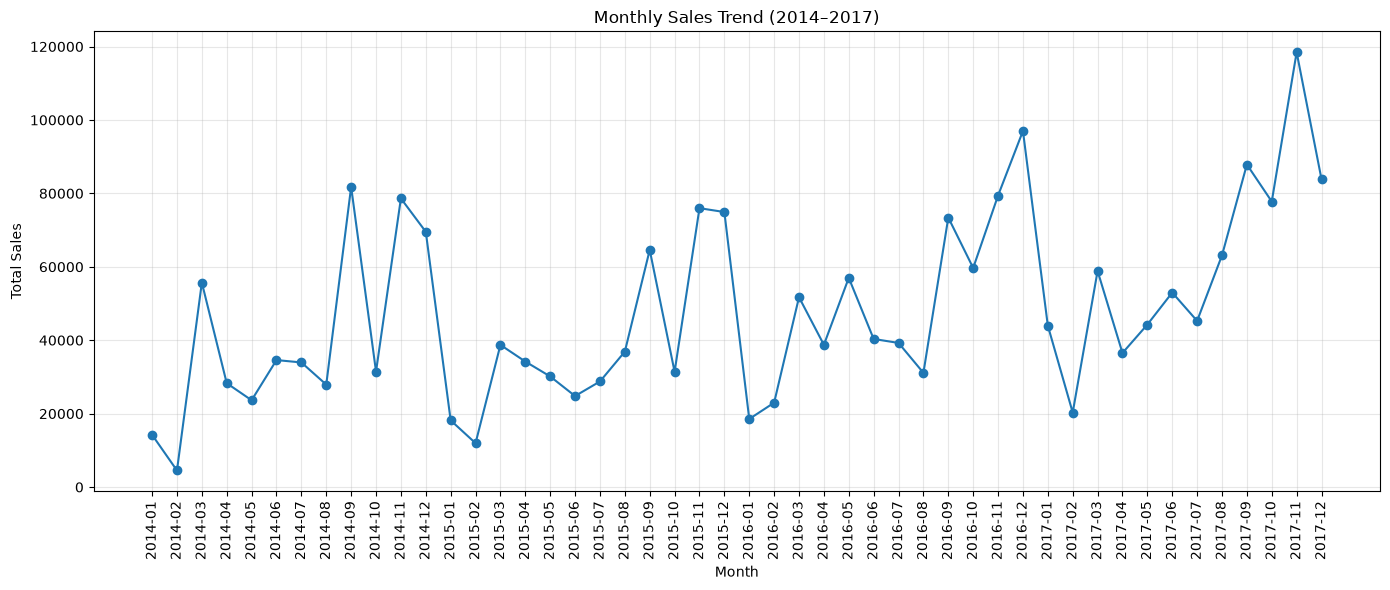

In [40]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o",
    linewidth=1.5
)

plt.title("Monthly Sales Trend (2014–2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**What this code does:** Prints the highest- and lowest-sales months with their sales values.

In [41]:
print("Highest Sales Month:")
print(monthly_sales.idxmax(), monthly_sales.max())

print("\nLowest Sales Month:")
print(monthly_sales.idxmin(), monthly_sales.min())

Highest Sales Month:
2017-11 118447.825

Lowest Sales Month:
2014-02 4519.892


**What this code does:** Calculates yearly sales totals.

In [42]:
df["Year"] = df["Order Date"].dt.year

yearly_sales = df.groupby("Year")["Sales"].sum()

yearly_sales


Year
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64

**What this code does:** Plots year-wise sales performance.

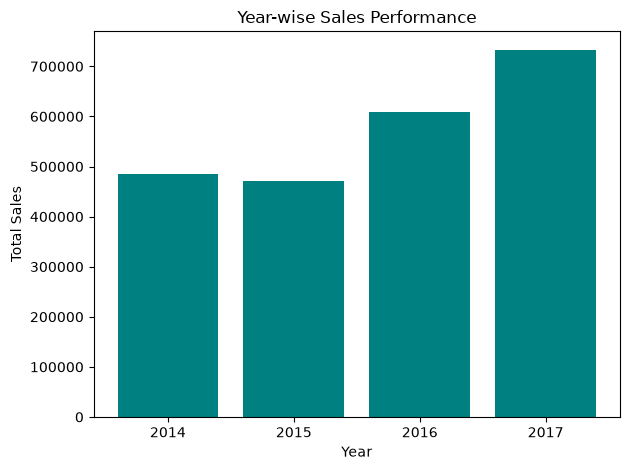

In [43]:
plt.bar(
    yearly_sales.index.astype(str),
    yearly_sales.values,
    color="teal"
)

plt.title("Year-wise Sales Performance")
plt.xlabel("Year")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

**What this code does:** Calculates percentage sales growth from one year to the next.

In [44]:
yearly_growth = yearly_sales.pct_change() * 100

yearly_growth = yearly_growth.round(2)

print("Year-wise Sales Growth (%)")
yearly_growth

Year-wise Sales Growth (%)


Year
2014      NaN
2015    -2.83
2016    29.47
2017    20.36
Name: Sales, dtype: float64

**What this code does:** Plots year-wise sales growth, distinguishing positive and negative growth.

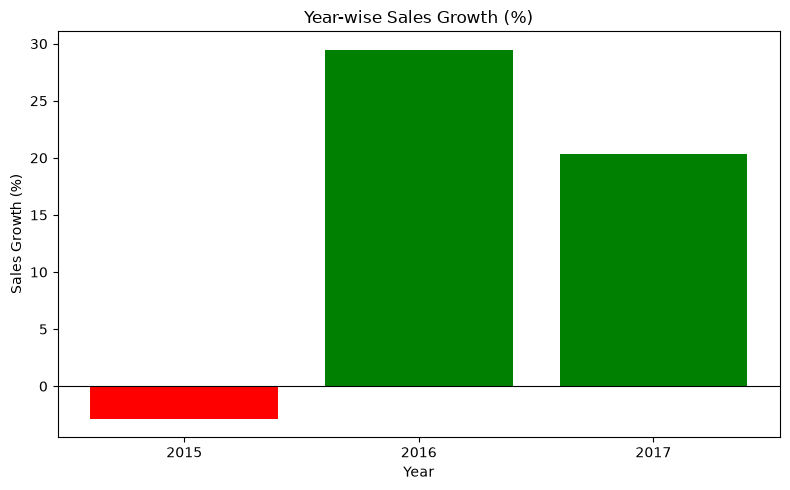

In [45]:
growth_data = yearly_growth.dropna()

plt.figure(figsize=(8, 5))

plt.bar(
    growth_data.index.astype(str),
    growth_data.values,
    color=[
        "red" if value < 0 else "green"
        for value in growth_data.values
    ]
)

plt.axhline(y=0, color="black", linewidth=0.8)

plt.title("Year-wise Sales Growth (%)")
plt.xlabel("Year")
plt.ylabel("Sales Growth (%)")

plt.tight_layout()
plt.show()

**What this code does:** Recalculates monthly sales totals for use in subsequent analysis.

In [46]:
monthly_sales = df.groupby("Month")["Sales"].sum()

**What this code does:** Aggregates sales by quarter.

In [47]:
df["Quarter"] = df["Order Date"].dt.to_period("Q")

quarterly_sales = df.groupby("Quarter")["Sales"].sum()

quarterly_sales

Quarter
2014Q1     74447.7960
2014Q2     86538.7596
2014Q3    143633.2123
2014Q4    179627.7302
2015Q1     68851.7386
2015Q2     89124.1870
2015Q3    130259.5752
2015Q4    182297.0082
2016Q1     93237.1810
2016Q2    136082.3010
2016Q3    143787.3622
2016Q4    236098.7538
2017Q1    123144.8602
2017Q2    133764.3720
2017Q3    196251.9560
2017Q4    280054.0670
Freq: Q-DEC, Name: Sales, dtype: float64

**What this code does:** Plots quarterly sales performance.

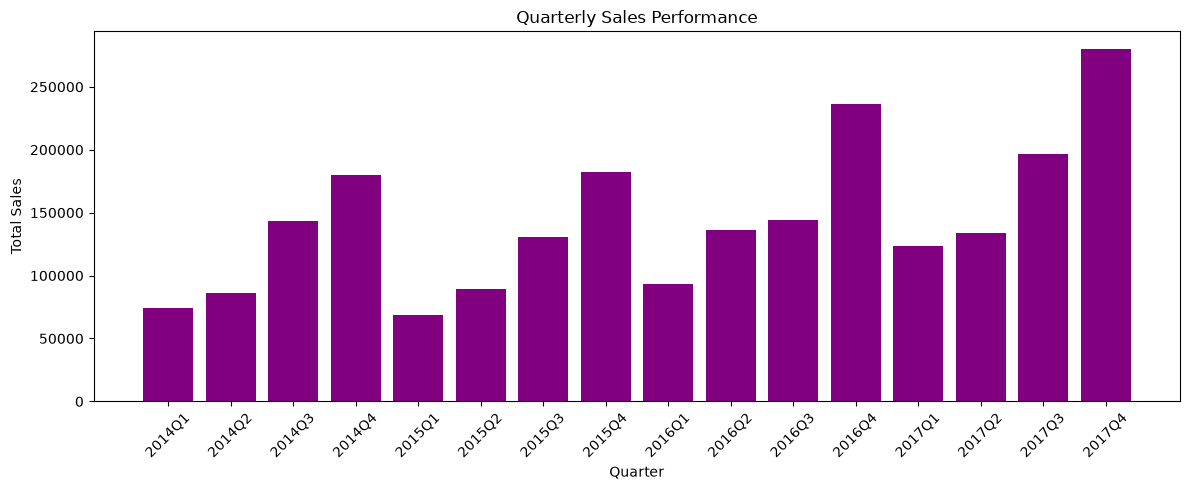

In [48]:
plt.figure(figsize=(12, 5))

plt.bar(
    quarterly_sales.index.astype(str),
    quarterly_sales.values,
    color="purple"
)

plt.title("Quarterly Sales Performance")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Interpretation and Results

Annual sales were **$484,247.50** in 2014, **$470,532.51** in 2015, **$609,205.60** in 2016, and **$733,215.26** in 2017. Sales declined in 2015 and then increased in 2016 and 2017. The highest-sales month was **2017-11 ($118,447.83)**, while the lowest-sales month was **2014-02 ($4,519.89)**. These values are calculated from the supplied 9,994-row CSV.


# Objective 3: Regional Sales and Profitability Analysis

This objective compares sales, profit, and profit margin across the four regions to identify the strongest and weakest regional performance.

**What this code does:** Aggregates total sales and total profit by region.

In [49]:
region_data = df_clean.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

region_data

,Total_Sales,Total_Profit
Region,,
Central,501239.8908,39706.3625
East,678781.2400,91522.7800
South,391721.9050,46749.4303
West,725457.8245,108418.4489


**What this code does:** Calculates regional profit margin as a percentage of sales.

In [50]:
region_data["Profit_Margin"] = (
    region_data["Total_Profit"] / region_data["Total_Sales"]
) * 100

region_data

,Total_Sales,Total_Profit,Profit_Margin
Region,,,
Central,501239.8908,39706.3625,7.921629
East,678781.2400,91522.7800,13.483399
South,391721.9050,46749.4303,11.934342
West,725457.8245,108418.4489,14.944831


**What this code does:** Prepares a region-wise summary of sales, profit, and profit margin, sorted by sales.

In [51]:
# REGIONAL SALES, PROFIT AND PROFIT MARGIN ANALYSIS

region_data = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

region_data["Profit_Margin"] = (
    region_data["Total_Profit"] /
    region_data["Total_Sales"]
) * 100

region_data.sort_values(
    "Total_Sales",
    ascending=False
).round(2)

,Total_Sales,Total_Profit,Profit_Margin
Region,,,
West,725457.82,108418.45,14.94
East,678781.24,91522.78,13.48
Central,501239.89,39706.36,7.92
South,391721.90,46749.43,11.93


**What this code does:** Plots total sales by region.

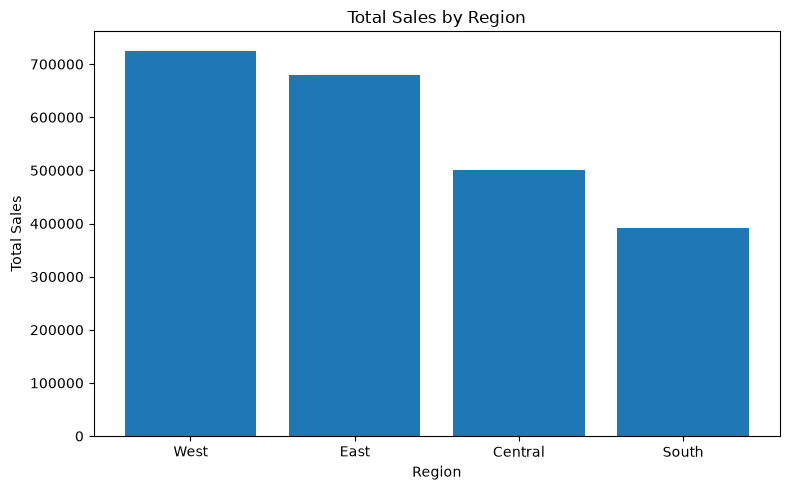

In [52]:
# TOTAL SALES BY REGION

import matplotlib.pyplot as plt

sales_by_region = region_data.sort_values(
    "Total_Sales", ascending=False
)

plt.figure(figsize=(8, 5))

plt.bar(
    sales_by_region.index,
    sales_by_region["Total_Sales"]
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**What this code does:** Plots total profit by region.

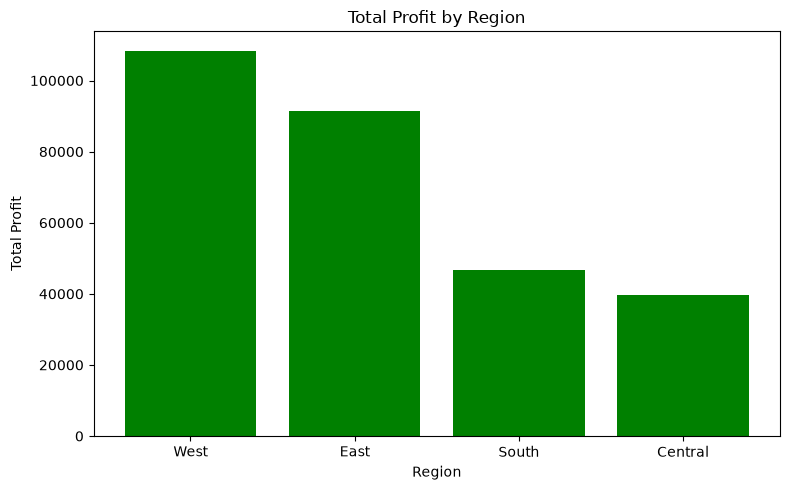

In [53]:
# TOTAL PROFIT BY REGION
profit_by_region = region_data.sort_values(
    "Total_Profit", ascending=False
)

plt.figure(figsize=(8, 5))

plt.bar(
    profit_by_region.index,
    profit_by_region["Total_Profit"],
    color="green"
)

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**What this code does:** Plots profit margin by region.

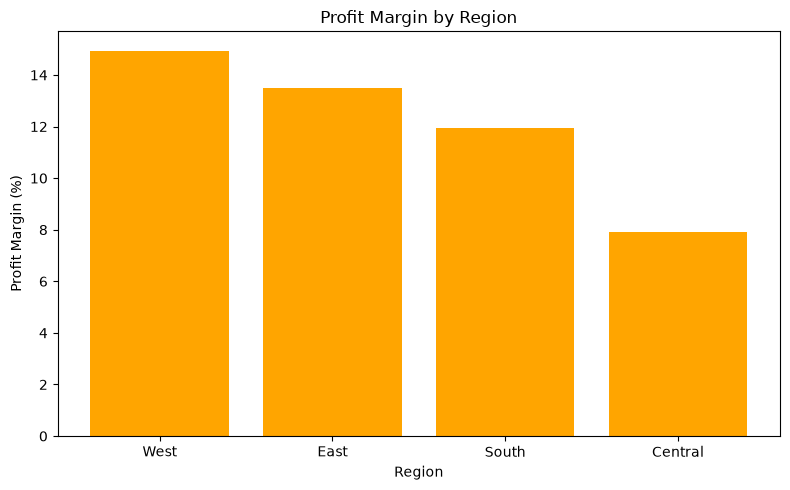

In [54]:
#PROFIT MARGIN BY REGION

margin_by_region = region_data.sort_values(
    "Profit_Margin", ascending=False
)

plt.figure(figsize=(8, 5))

plt.bar(
    margin_by_region.index,
    margin_by_region["Profit_Margin"],
    color="orange"
)

plt.title("Profit Margin by Region")
plt.xlabel("Region")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation and Results

The **West** region recorded the highest sales (**$725,457.82**) and highest profit (**$108,418.45**), with a profit margin of **14.94%**. The **Central** region had the lowest total regional profit (**$39,706.36**) and the lowest profit margin (**7.92%**) among the four regions. Regional profit margins differ, so sales volume alone should not be used to judge regional performance.


# Objective 4: Category and Sub-Category Performance Analysis

This objective compares sales, profit, and profit margin across product categories and sub-categories. It also examines regional sales and profit by product category.

**What this code does:** Aggregates sales and profit by sub-category and sorts the results by profit.

In [55]:
subcategory_data = df_clean.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

subcategory_data.sort_values("Total_Profit")

,Total_Sales,Total_Profit
Sub-Category,,
Tables,206965.5320,-17725.4811
Bookcases,114879.9963,-3472.5560
Supplies,46673.5380,-1189.0995
Fasteners,3024.2800,949.5182
Machines,189238.6310,3384.7569
Labels,12486.3120,5546.2540
Art,27118.7920,6527.7870
Envelopes,16476.4020,6964.1767
Furnishings,91705.1640,13059.1436


**What this code does:** Aggregates total sales and profit by product category.

In [56]:
category_data = df_clean.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

category_data

,Total_Sales,Total_Profit
Category,,
Furniture,741999.7953,18451.2728
Office Supplies,719047.0320,122490.8008
Technology,836154.0330,145454.9481


**What this code does:** Calculates profit margin for each product category.

In [57]:
category_data["Profit_Margin"] = (
    category_data["Total_Profit"] /
    category_data["Total_Sales"]
) * 100

category_data.round(2)

,Total_Sales,Total_Profit,Profit_Margin
Category,,,
Furniture,741999.80,18451.27,2.49
Office Supplies,719047.03,122490.80,17.04
Technology,836154.03,145454.95,17.40


**What this code does:** Summarizes the minimum, maximum, and mean category sales, profit, and margin.

In [58]:
category_data[["Total_Sales", "Total_Profit", "Profit_Margin"]].agg(
    ["min", "max", "mean"]
).round(2)

,Total_Sales,Total_Profit,Profit_Margin
min,719047.03,18451.27,2.49
max,836154.03,145454.95,17.40
mean,765733.62,95465.67,12.31


**What this code does:** Calculates sub-category profit margins and displays the results sorted by profit.

In [59]:
subcategory_data["Profit_Margin"] = (
    subcategory_data["Total_Profit"] /
    subcategory_data["Total_Sales"]
) * 100

subcategory_data.sort_values("Total_Profit").round(2)

,Total_Sales,Total_Profit,Profit_Margin
Sub-Category,,,
Tables,206965.53,-17725.48,-8.56
Bookcases,114880.00,-3472.56,-3.02
Supplies,46673.54,-1189.10,-2.55
Fasteners,3024.28,949.52,31.40
Machines,189238.63,3384.76,1.79
Labels,12486.31,5546.25,44.42
Art,27118.79,6527.79,24.07
Envelopes,16476.40,6964.18,42.27
Furnishings,91705.16,13059.14,14.24


**What this code does:** Identifies the highest- and lowest-profit sub-categories.

In [60]:
print("Highest Profit Sub-Category:", subcategory_data["Total_Profit"].idxmax())
print("Lowest Profit Sub-Category:", subcategory_data["Total_Profit"].idxmin())

Highest Profit Sub-Category: Copiers
Lowest Profit Sub-Category: Tables


**What this code does:** Creates a category-level sales and profit summary.

In [61]:
# CATEGORY-WISE SALES AND PROFIT ANALYSIS

category_data = region_data

category_summary = df.groupby("Category").agg({
    "Sales": "sum",
    "Profit": "sum"
})

category_summary = category_summary.sort_values(
    "Sales", ascending=False
)

category_summary

,Sales,Profit
Category,,
Technology,836154.0330,145454.9481
Furniture,741999.7953,18451.2728
Office Supplies,719047.0320,122490.8008


**What this code does:** Displays side-by-side bar charts comparing sales and profit by category.

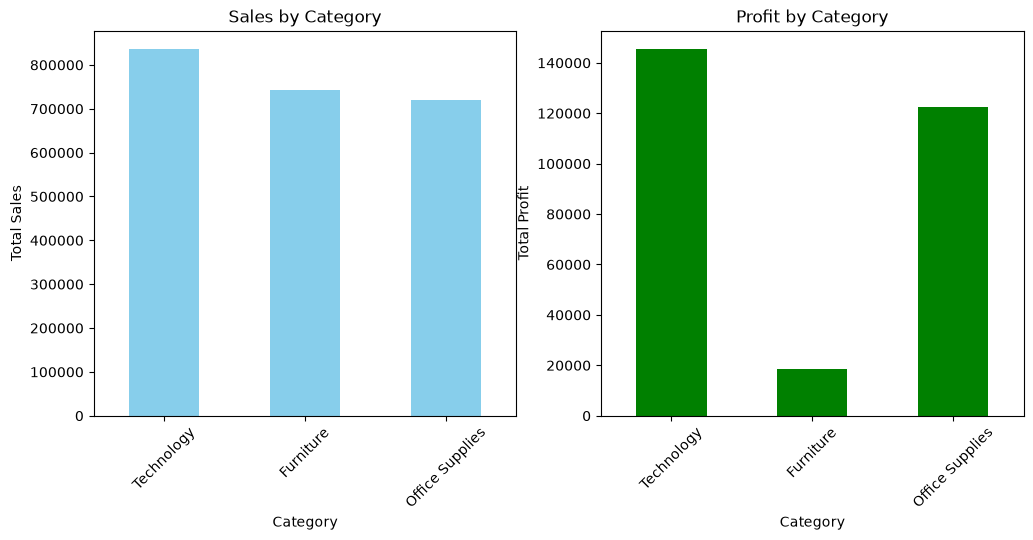

In [62]:
# SALES AND PROFIT COMPARISON BY CATEGORY

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Sales by Category
category_summary["Sales"].plot(
    kind="bar",
    ax=axes[0],
    color="skyblue"
)

axes[0].set_title("Sales by Category")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Total Sales")
axes[0].tick_params(axis="x", rotation=45)

# Profit by Category
category_summary["Profit"].plot(
    kind="bar",
    ax=axes[1],
    color="green"
)

axes[1].set_title("Profit by Category")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Total Profit")
axes[1].tick_params(axis="x", rotation=45)

**What this code does:** Creates a sub-category-level sales and profit summary.

In [63]:
# SUB-CATEGORY-WISE SALES AND PROFIT ANALYSIS
subcategory_summary = df.groupby("Sub-Category").agg({
    "Sales": "sum",
    "Profit": "sum"
})

subcategory_summary = subcategory_summary.sort_values(
    "Profit", ascending=False
)

subcategory_summary

,Sales,Profit
Sub-Category,,
Copiers,149528.0300,55617.8249
Phones,330007.0540,44515.7306
Accessories,167380.3180,41936.6357
Paper,78479.2060,34053.5693
Binders,203412.7330,30221.7633
Chairs,328449.1030,26590.1663
Storage,223843.6080,21278.8264
Appliances,107532.1610,18138.0054
Furnishings,91705.1640,13059.1436


**What this code does:** Displays the five lowest-profit sub-categories from the summary.

In [64]:
subcategory_summary.tail(5)

,Sales,Profit
Sub-Category,,
Machines,189238.6310,3384.7569
Fasteners,3024.2800,949.5182
Supplies,46673.5380,-1189.0995
Bookcases,114879.9963,-3472.5560
Tables,206965.5320,-17725.4811


**What this code does:** Plots total profit by sub-category, distinguishing loss-making and profitable groups.

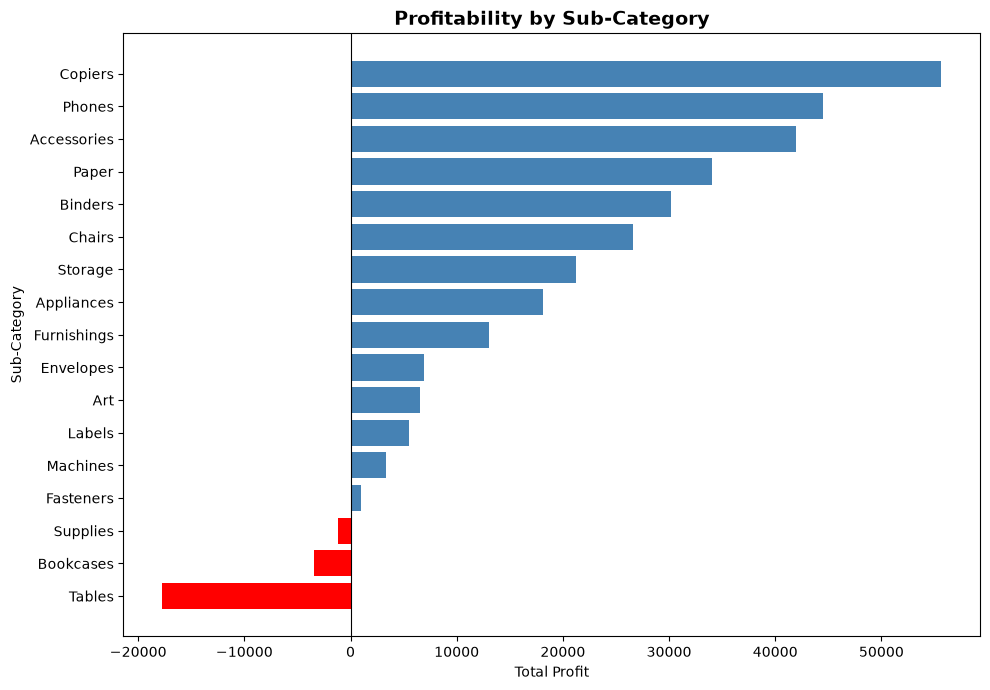

In [65]:
# PROFITABILITY ANALYSIS BY SUB-CATEGORY

profit_data = (
    df.groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values(ascending=True)
)

colors = [
    "red" if profit < 0 else "steelblue"
    for profit in profit_data
]

plt.figure(figsize=(10, 7))

plt.barh(
    profit_data.index,
    profit_data.values,
    color=colors
)

plt.axvline(x=0, color="black", linewidth=0.8)

plt.title(
    "Profitability by Sub-Category",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")

plt.tight_layout()
plt.show()

**What this code does:** Displays a sales-versus-profit table and scatter plot for each sub-category.

,Sales,Profit
Sub-Category,,
Accessories,167380.32,41936.64
Appliances,107532.16,18138.01
Art,27118.79,6527.79
Binders,203412.73,30221.76
Bookcases,114880.00,-3472.56
Chairs,328449.10,26590.17
Copiers,149528.03,55617.82
Envelopes,16476.40,6964.18
Fasteners,3024.28,949.52


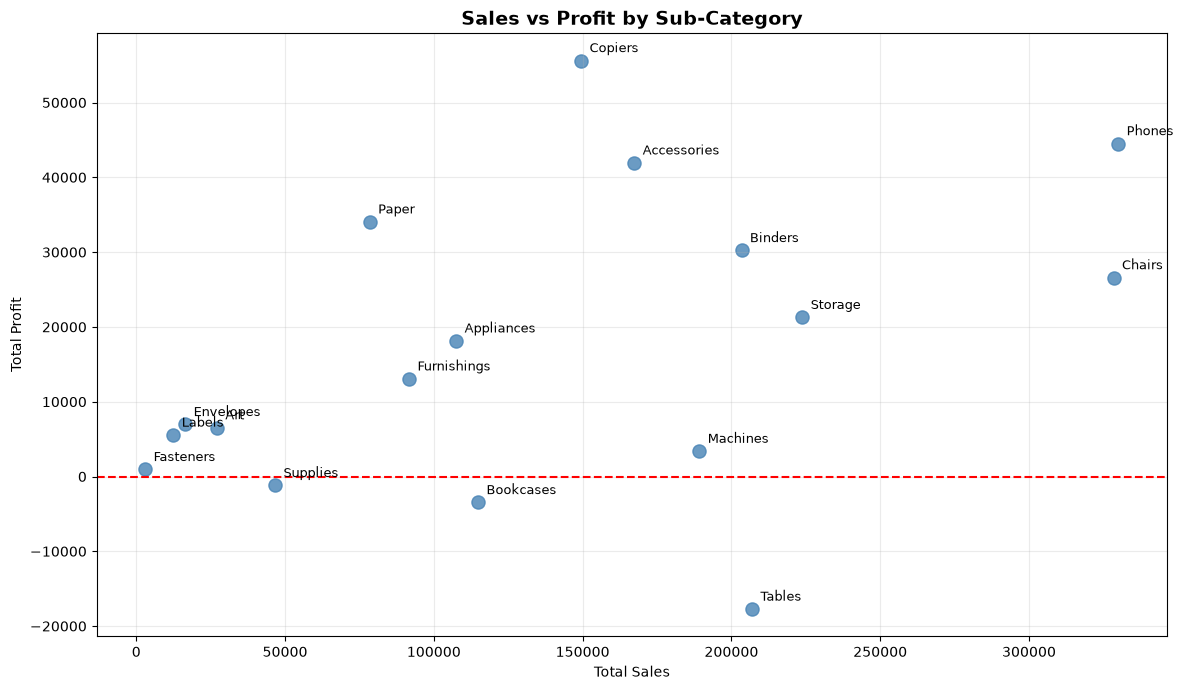

In [66]:
# SALES VS PROFIT BY SUB-CATEGORY

# Create a separate DataFrame
subcategory_sales_profit_df = df.groupby(
    "Sub-Category"
).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

# Display Table
display(subcategory_sales_profit_df.round(2))

# Scatter Plot
plt.figure(figsize=(12, 7))

plt.scatter(
    subcategory_sales_profit_df["Sales"],
    subcategory_sales_profit_df["Profit"],
    color="steelblue",
    s=90,
    alpha=0.8
)

for name, row in subcategory_sales_profit_df.iterrows():
    plt.annotate(
        name,
        (row["Sales"], row["Profit"]),
        fontsize=9,
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.axhline(y=0, color="red", linestyle="--")

plt.title(
    "Sales vs Profit by Sub-Category",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Total Sales")
plt.ylabel("Total Profit")

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**What this code does:** Creates a pivot table of sales by region and product category.

In [67]:
region_category = df.pivot_table(
    index="Region",
    columns="Category",
    values="Sales",
    aggfunc="sum"
)

region_category

Category,Furniture,Office Supplies,Technology
Region,,,
Central,163797.1638,167026.415,170416.312
East,208291.2040,205516.055,264973.981
South,117298.6840,125651.313,148771.908
West,252612.7435,220853.249,251991.832


**What this code does:** Plots regional sales by product category.

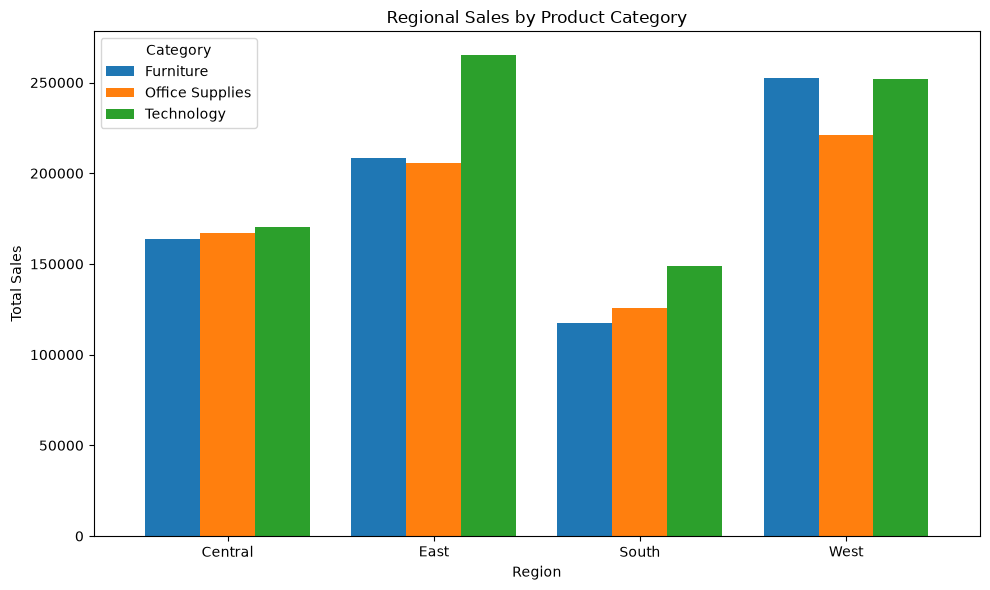

In [68]:
region_category.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Regional Sales by Product Category")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

**What this code does:** Creates a pivot table of profit by region and product category.

In [69]:
region_profit = df.pivot_table(
    index="Region",
    columns="Category",
    values="Profit",
    aggfunc="sum"
)

region_profit

Category,Furniture,Office Supplies,Technology
Region,,,
Central,-2871.0494,8879.9799,33697.4320
East,3046.1658,41014.5791,47462.0351
South,6771.2061,19986.3928,19991.8314
West,11504.9503,52609.8490,44303.6496


**What this code does:** Plots regional profit by product category.

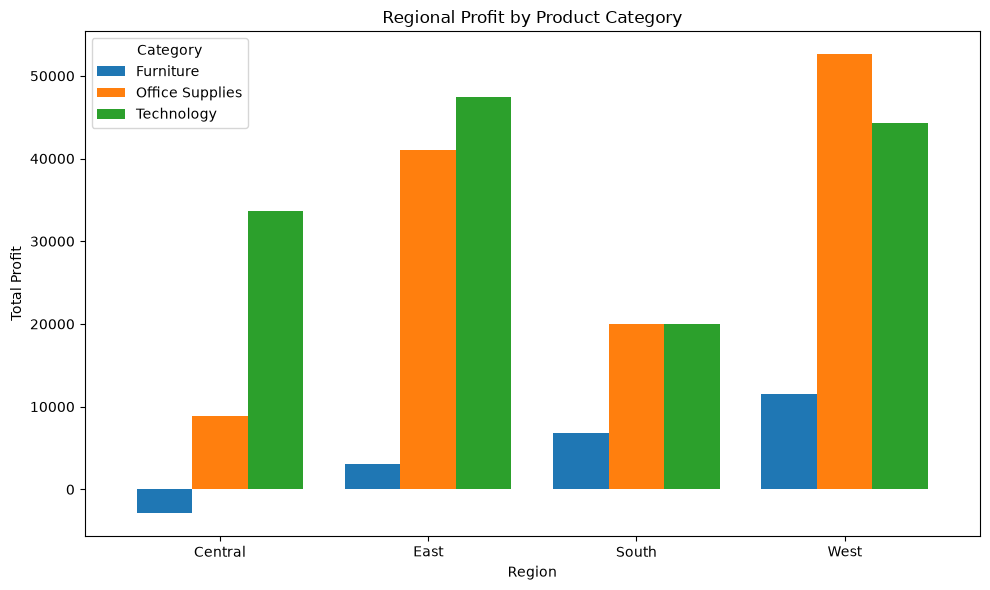

In [70]:
region_profit.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Regional Profit by Product Category")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

**What this code does:** Calculates category-level profit margins.

In [71]:
category_summary["Profit_Margin"] = (
    category_summary["Profit"] /
    category_summary["Sales"]
) * 100

category_summary["Profit_Margin"] = (
    category_summary["Profit_Margin"].round(2)
)

category_summary

,Sales,Profit,Profit_Margin
Category,,,
Technology,836154.0330,145454.9481,17.40
Furniture,741999.7953,18451.2728,2.49
Office Supplies,719047.0320,122490.8008,17.04


**What this code does:** Plots profit margin by product category.

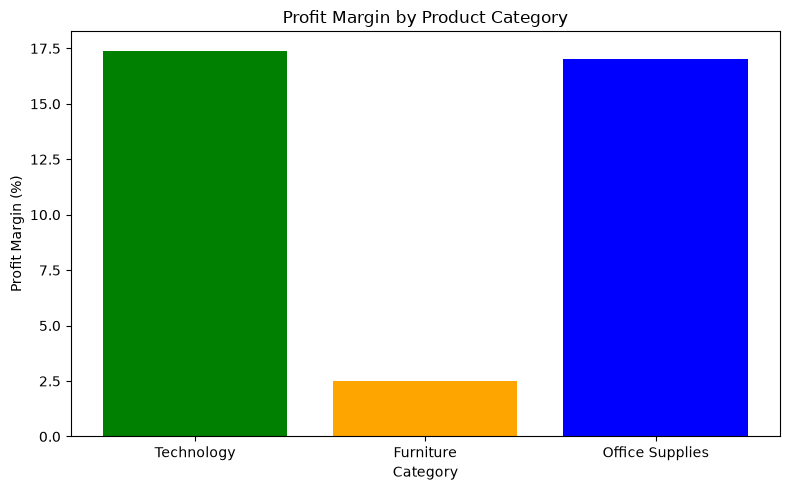

In [72]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_summary.index,
    category_summary["Profit_Margin"],
    color=["green", "orange", "blue"]
)

plt.title("Profit Margin by Product Category")
plt.xlabel("Category")
plt.ylabel("Profit Margin (%)")

plt.tight_layout()
plt.show()

### Interpretation and Results

**Technology** generated the highest category profit (**$145,454.95**). **Furniture** had the lowest category profit margin (**2.49%**). At sub-category level, **Copiers** produced the highest total profit (**$55,617.82**), while **Tables** produced the lowest total profit (**$-17,725.48**).

# Objective 5: Discount Impact, Customer Segment and State-wise Sales Analysis

This objective examines how discount levels relate to profit, compares sales and profit across customer segments, and identifies the ten states with the highest sales.

**What this code does:** Counts records at each discount level.

In [73]:
df_clean["Discount"].value_counts().sort_index()

Discount
0.00    4798
0.10      94
0.15      52
0.20    3657
0.30     227
0.32      27
0.40     206
0.45      11
0.50      66
0.60     138
0.70     418
0.80     300
Name: count, dtype: int64

**What this code does:** Summarizes average profit, total profit, and record count by discount level.

In [74]:
discount_data = df_clean.groupby("Discount").agg(
    Average_Profit=("Profit", "mean"),
    Total_Profit=("Profit", "sum"),
    Number_of_Records=("Profit", "count")
)

discount_data

,Average_Profit,Total_Profit,Number_of_Records
Discount,,,
0.00,66.900292,320987.6032,4798
0.10,96.055074,9029.1770,94
0.15,27.288298,1418.9915,52
0.20,24.702572,90337.3060,3657
0.30,-45.679636,-10369.2774,227
0.32,-88.560656,-2391.1377,27
0.40,-111.927429,-23057.0504,206
0.45,-226.646464,-2493.1111,11
0.50,-310.703456,-20506.4281,66


**What this code does:** Summarizes average order profit, total profit, and unique order count by discount level.


In [75]:

# Calculate total profit for each individual order at each discount level
order_discount_profit = (
    df_clean.groupby(["Discount", "Order ID"], as_index=False)
    .agg(Order_Profit=("Profit", "sum"))
)

# Summarize average order profit, total profit, and number of orders by discount
discount_data = (
    order_discount_profit.groupby("Discount")
    .agg(
        Average_Profit=("Order_Profit", "mean"),
        Total_Profit=("Order_Profit", "sum"),
        Number_of_Orders=("Order ID", "nunique")
    )
    .round(2)
)

discount_data


,Average_Profit,Total_Profit,Number_of_Orders
Discount,,,
0.00,121.40,320987.60,2644
0.10,101.45,9029.18,89
0.15,27.82,1418.99,51
0.20,37.53,90337.31,2407
0.30,-49.14,-10369.28,211
0.32,-88.56,-2391.14,27
0.40,-124.63,-23057.05,185
0.45,-249.31,-2493.11,10
0.50,-320.41,-20506.43,64



## Discount vs Profit Analysis

This analysis examines the relationship between discount levels and profit.

The objective is to understand how increasing discounts affect profitability and identify whether higher discounts are associated with losses.


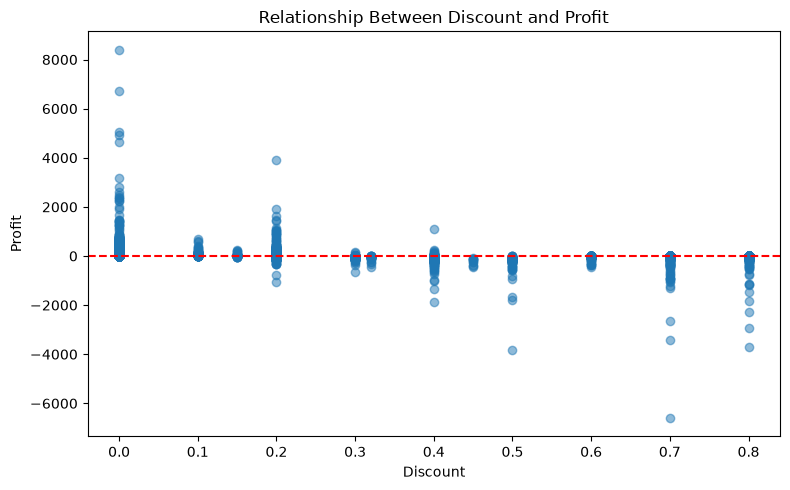

In [76]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Discount"],
    df["Profit"],
    alpha=0.5
)

plt.title("Relationship Between Discount and Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.axhline(y=0, color="red", linestyle="--")

plt.tight_layout()
plt.show()


**What this code does:** Compares average discount, total profit, and sales across product categories.

In [77]:
discount_summary = df.groupby("Category").agg({
    "Discount": "mean",
    "Profit": "sum",
    "Sales": "sum"
})

discount_summary["Discount"] = (
    discount_summary["Discount"] * 100
).round(2)

discount_summary

,Discount,Profit,Sales
Category,,,
Furniture,17.39,18451.2728,741999.7953
Office Supplies,15.73,122490.8008,719047.0320
Technology,13.23,145454.9481,836154.0330


**What this code does:** Aggregates sales and profit for each discount level.

In [78]:
discount_summary = df.groupby("Discount").agg({
    "Sales": "sum",
    "Profit": "sum"
})

discount_summary = discount_summary.round(2)

discount_summary

,Sales,Profit
Discount,,
0.00,1087908.47,320987.60
0.10,54369.35,9029.18
0.15,27558.52,1418.99
0.20,764594.37,90337.31
0.30,103226.66,-10369.28
0.32,14493.46,-2391.14
0.40,116417.78,-23057.05
0.45,5484.97,-2493.11
0.50,58918.54,-20506.43


**What this code does:** Plots the discount summary using the original chart code and retained output.

**Execution note:** Restores the category-level discount summary required by the original chart below. The discount-level table from the preceding original cell remains displayed above.


In [79]:
discount_summary = df.groupby("Category").agg({
    "Discount": "mean",
    "Profit": "sum",
    "Sales": "sum"
})

discount_summary["Discount"] = (discount_summary["Discount"] * 100).round(2)


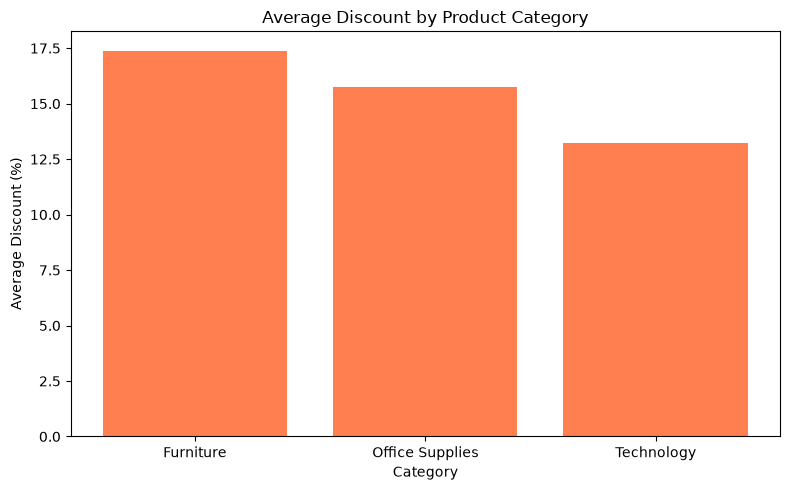

In [80]:
plt.figure(figsize=(8, 5))

plt.bar(
    discount_summary.index,
    discount_summary["Discount"],
    color="coral"
)

plt.title("Average Discount by Product Category")
plt.xlabel("Category")
plt.ylabel("Average Discount (%)")

plt.tight_layout()
plt.show()

**What this code does:** Calculates the correlation between discount and profit.

In [81]:
discount_profit_corr = df["Discount"].corr(
    df["Profit"]
)

print("Correlation between Discount and Profit:",
      round(discount_profit_corr, 3))

Correlation between Discount and Profit: -0.219


**What this code does:** Aggregates sales and profit by customer segment.

In [82]:
segment_summary = df.groupby("Segment").agg({
    "Sales": "sum",
    "Profit": "sum"
})

segment_summary

,Sales,Profit
Segment,,
Consumer,1.161401e+06,134119.2092
Corporate,7.061464e+05,91979.1340
Home Office,4.296531e+05,60298.6785


**What this code does:** Plots sales and profit for each customer segment.

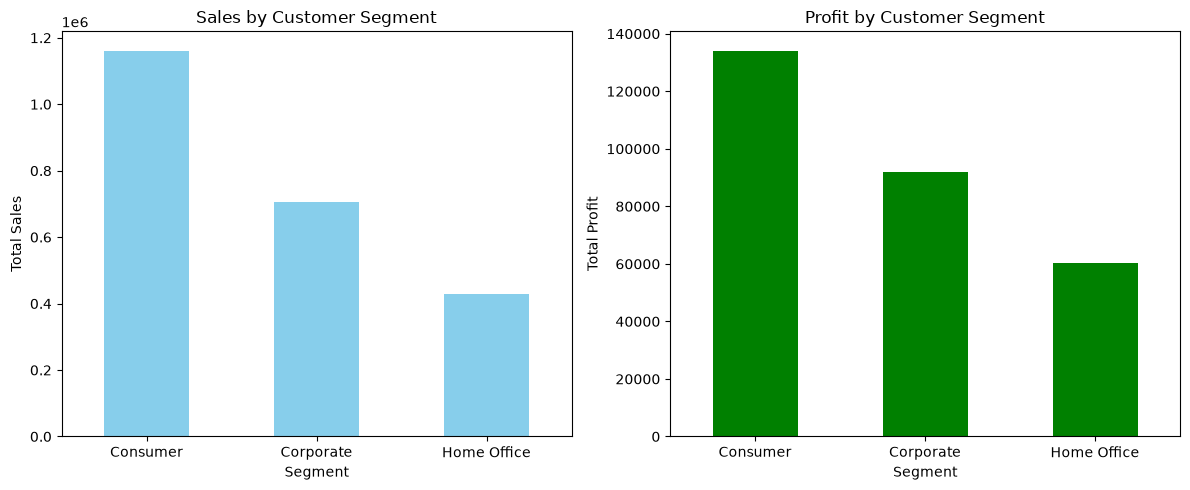

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

segment_summary["Sales"].plot(
    kind="bar",
    ax=axes[0],
    color="skyblue"
)

axes[0].set_title("Sales by Customer Segment")
axes[0].set_xlabel("Segment")
axes[0].set_ylabel("Total Sales")
axes[0].tick_params(axis="x", rotation=0)

segment_summary["Profit"].plot(
    kind="bar",
    ax=axes[1],
    color="green"
)

axes[1].set_title("Profit by Customer Segment")
axes[1].set_xlabel("Segment")
axes[1].set_ylabel("Total Profit")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**What this code does:** Identifies the ten states with the highest total sales.

In [84]:
state_sales = df.groupby("State")["Sales"].sum()

top_10_states = state_sales.sort_values(
    ascending=False
).head(10)

top_10_states

State
California      457687.6315
New York        310876.2710
Texas           170188.0458
Washington      138641.2700
Pennsylvania    116511.9140
Florida          89473.7080
Illinois         80166.1010
Ohio             78258.1360
Michigan         76269.6140
Virginia         70636.7200
Name: Sales, dtype: float64

**What this code does:** Plots the top ten states by sales.

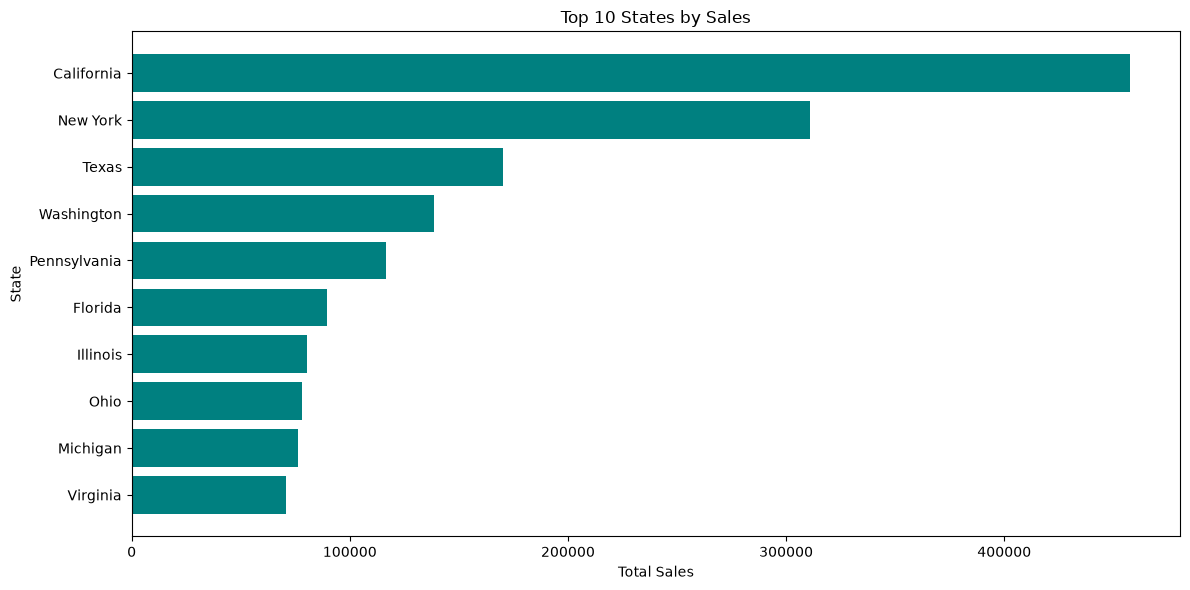

In [85]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_states.index,
    top_10_states.values,
    color="teal"
)

plt.title("Top 10 States by Sales")
plt.xlabel("Total Sales")
plt.ylabel("State")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Interpretation and Results

The transaction-level correlation between discount and profit is **-0.219**, indicating a negative association in this dataset; this does not by itself prove that discounts cause lower profit. The Consumer segment generated the highest sales (**$1,161,401.34**) and profit (**$134,119.21**). **California** was the highest-sales state (**$457,687.63**). At order level, average profit was **$37.53** at a **20%** discount across **2,407 orders**, and **-$49.14** at a **30%** discount across **211 orders**.


# Objective 6: Future Sales Forecasting and Model Comparison

This objective compares three monthly sales forecasting methods: the 3-month moving average, the 6-month moving average, and the Seasonal Naive method. Forecast accuracy is evaluated using MAE, RMSE, and WAPE. The original forecasting comparison code and its result outputs are retained.

**What this setup code does:** Imports NumPy, which is required by the original forecasting calculation below.

In [86]:
import numpy as np


**What this code does:** Builds the three forecast series, compares their accuracy using MAE, RMSE, and WAPE, selects the method with the lowest WAPE, and estimates sales for the next month.

FORECASTING METHOD COMPARISON
        Method      MAE     RMSE  WAPE
    3-Month MA 18787.40 25181.42 30.75
    6-Month MA 21138.04 26827.71 34.60
Seasonal Naive 15467.89 18985.70 25.32

Best Forecasting Method: Seasonal Naive

NEXT MONTH SALES FORECAST
Forecast Month: January 2018
Forecasted Sales: $43,971.37


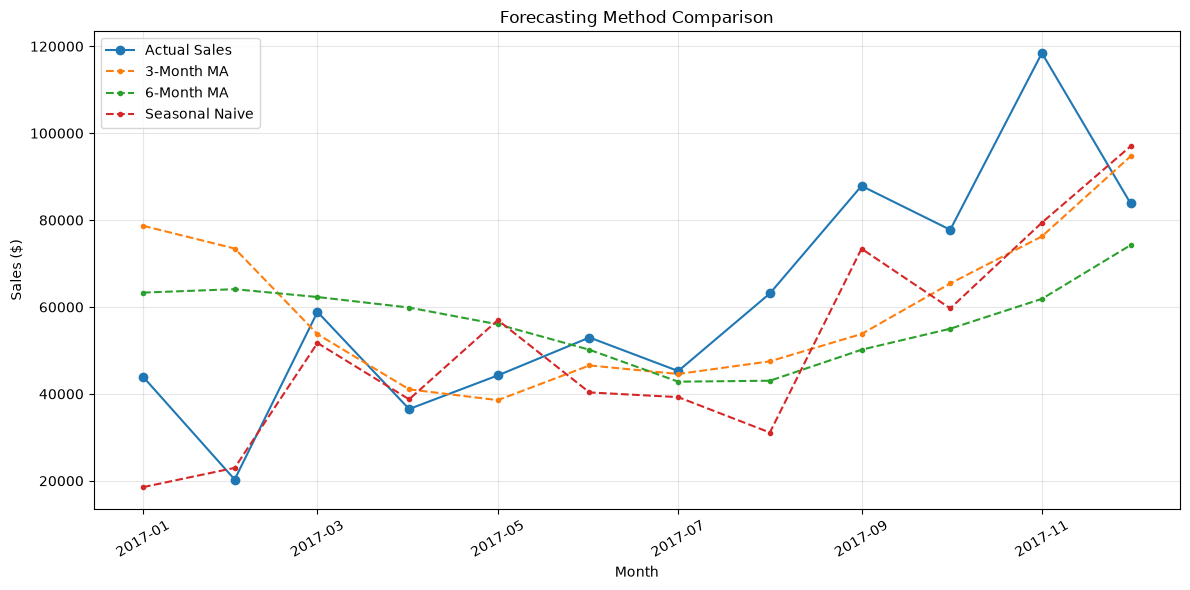

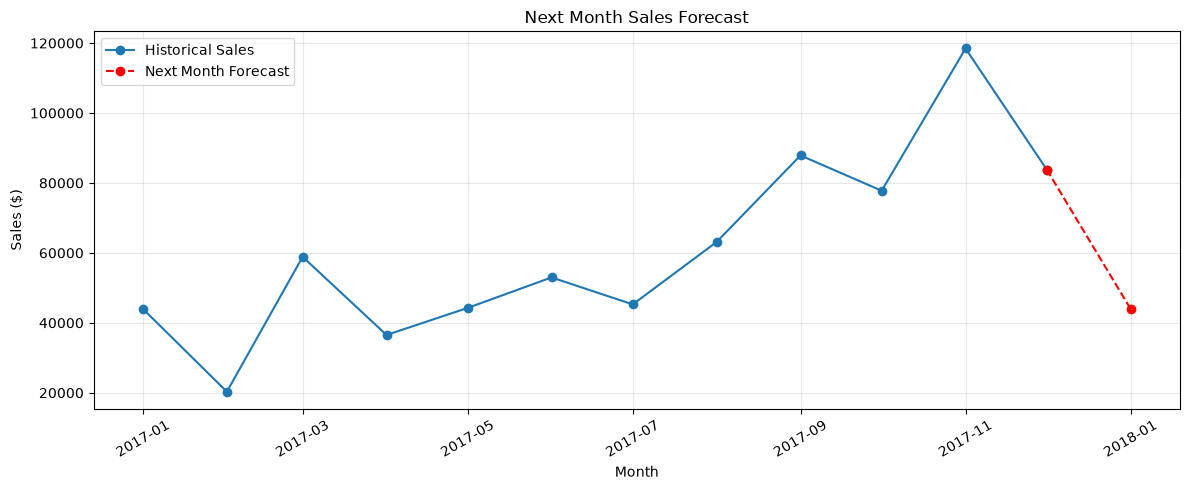

In [87]:
# ================================================
# OBJECTIVE 6: FORECASTING MODEL COMPARISON
# ================================================

# 1. Prepare Monthly Sales
sales = monthly_sales.copy()
sales = sales.sort_index().dropna()

# 2. Generate Three Forecasting Methods

forecast_3m = sales.shift(1).rolling(3).mean()

forecast_6m = sales.shift(1).rolling(6).mean()

seasonal_forecast = sales.shift(12)

# 3. Combine Predictions
comparison = pd.DataFrame({
    "Actual Sales": sales,
    "3-Month MA": forecast_3m,
    "6-Month MA": forecast_6m,
    "Seasonal Naive": seasonal_forecast
})

# Use the same last 12 months for fair comparison
comparison = comparison.dropna().tail(12)

# 4. Calculate Accuracy Metrics
results = []

for method in [
    "3-Month MA",
    "6-Month MA",
    "Seasonal Naive"
]:

    actual = comparison["Actual Sales"]
    predicted = comparison[method]

    mae = np.mean(np.abs(actual - predicted))

    rmse = np.sqrt(
        np.mean((actual - predicted) ** 2)
    )

    wape = (
        np.sum(np.abs(actual - predicted))
        / np.sum(np.abs(actual))
    ) * 100

    results.append({
        "Method": method,
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape
    })

# 5. Display Comparison
results_df = pd.DataFrame(results)

print("FORECASTING METHOD COMPARISON")
print(results_df.round(2).to_string(index=False))

# 6. Select Best Method Based on WAPE
best_method = results_df.loc[
    results_df["WAPE"].idxmin(), "Method"
]

print("\nBest Forecasting Method:", best_method)

# 7. Forecast Next Month
if best_method == "3-Month MA":
    next_forecast = sales.tail(3).mean()

elif best_method == "6-Month MA":
    next_forecast = sales.tail(6).mean()

else:
    next_forecast = sales.iloc[-12]
# Identify the next month
next_month = sales.index[-1] + 1

print("\nNEXT MONTH SALES FORECAST")
print("Forecast Month:", next_month.strftime("%B %Y"))
print(f"Forecasted Sales: ${next_forecast:,.2f}")
# ==========================================
# 8. PLOT FORECASTING COMPARISON
# ==========================================

# Convert PeriodIndex to DatetimeIndex
comparison_dates = comparison.index.to_timestamp()

plt.figure(figsize=(12, 6))

plt.plot(
    comparison_dates,
    comparison["Actual Sales"],
    marker="o",
    label="Actual Sales"
)

for method in [
    "3-Month MA",
    "6-Month MA",
    "Seasonal Naive"
]:
    plt.plot(
        comparison_dates,
        comparison[method],
        marker=".",
        linestyle="--",
        label=method
    )

plt.title("Forecasting Method Comparison")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.legend()
plt.xticks(rotation=30)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ==========================================
# 9. FINAL FORECAST GRAPH
# ==========================================

historical = sales.tail(12)

# Convert dates for plotting
historical_dates = historical.index.to_timestamp()
next_month_date = next_month.to_timestamp()

plt.figure(figsize=(12, 5))

plt.plot(
    historical_dates,
    historical.values,
    marker="o",
    label="Historical Sales"
)

plt.plot(
    [historical_dates[-1], next_month_date],
    [historical.iloc[-1], next_forecast],
    marker="o",
    linestyle="--",
    color="red",
    label="Next Month Forecast"
)

plt.title("Next Month Sales Forecast")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Interpretation and Results

The executed model comparison reports the following WAPE values on the same last 12-month evaluation window:

- 3-Month Moving Average: **30.75%**
- 6-Month Moving Average: **34.60%**
- Seasonal Naive: **25.32%**

The **Seasonal Naive** method achieved the lowest WAPE and was selected as the best-performing method among the three for this evaluation period. The forecast for **January 2018** is **$43,971.37**. This is an estimate based on the previous year's corresponding month, not a guaranteed result.


# Final Professional Dashboard – Regional Sales Pulse

The final dashboard code and its existing rendered output are retained at the end of the notebook.

**What this code does:** Builds the final Regional Sales Pulse dashboard with KPI cards, performance charts, business insights, and the Executive Midnight Navy & Platinum theme.


========== NEXT MONTH SALES FORECAST ==========
Forecast Method : Seasonal Naive
Forecast Month  : January 2018
Forecasted Sales: $43,971.37


NameError: name 'ax5' is not defined

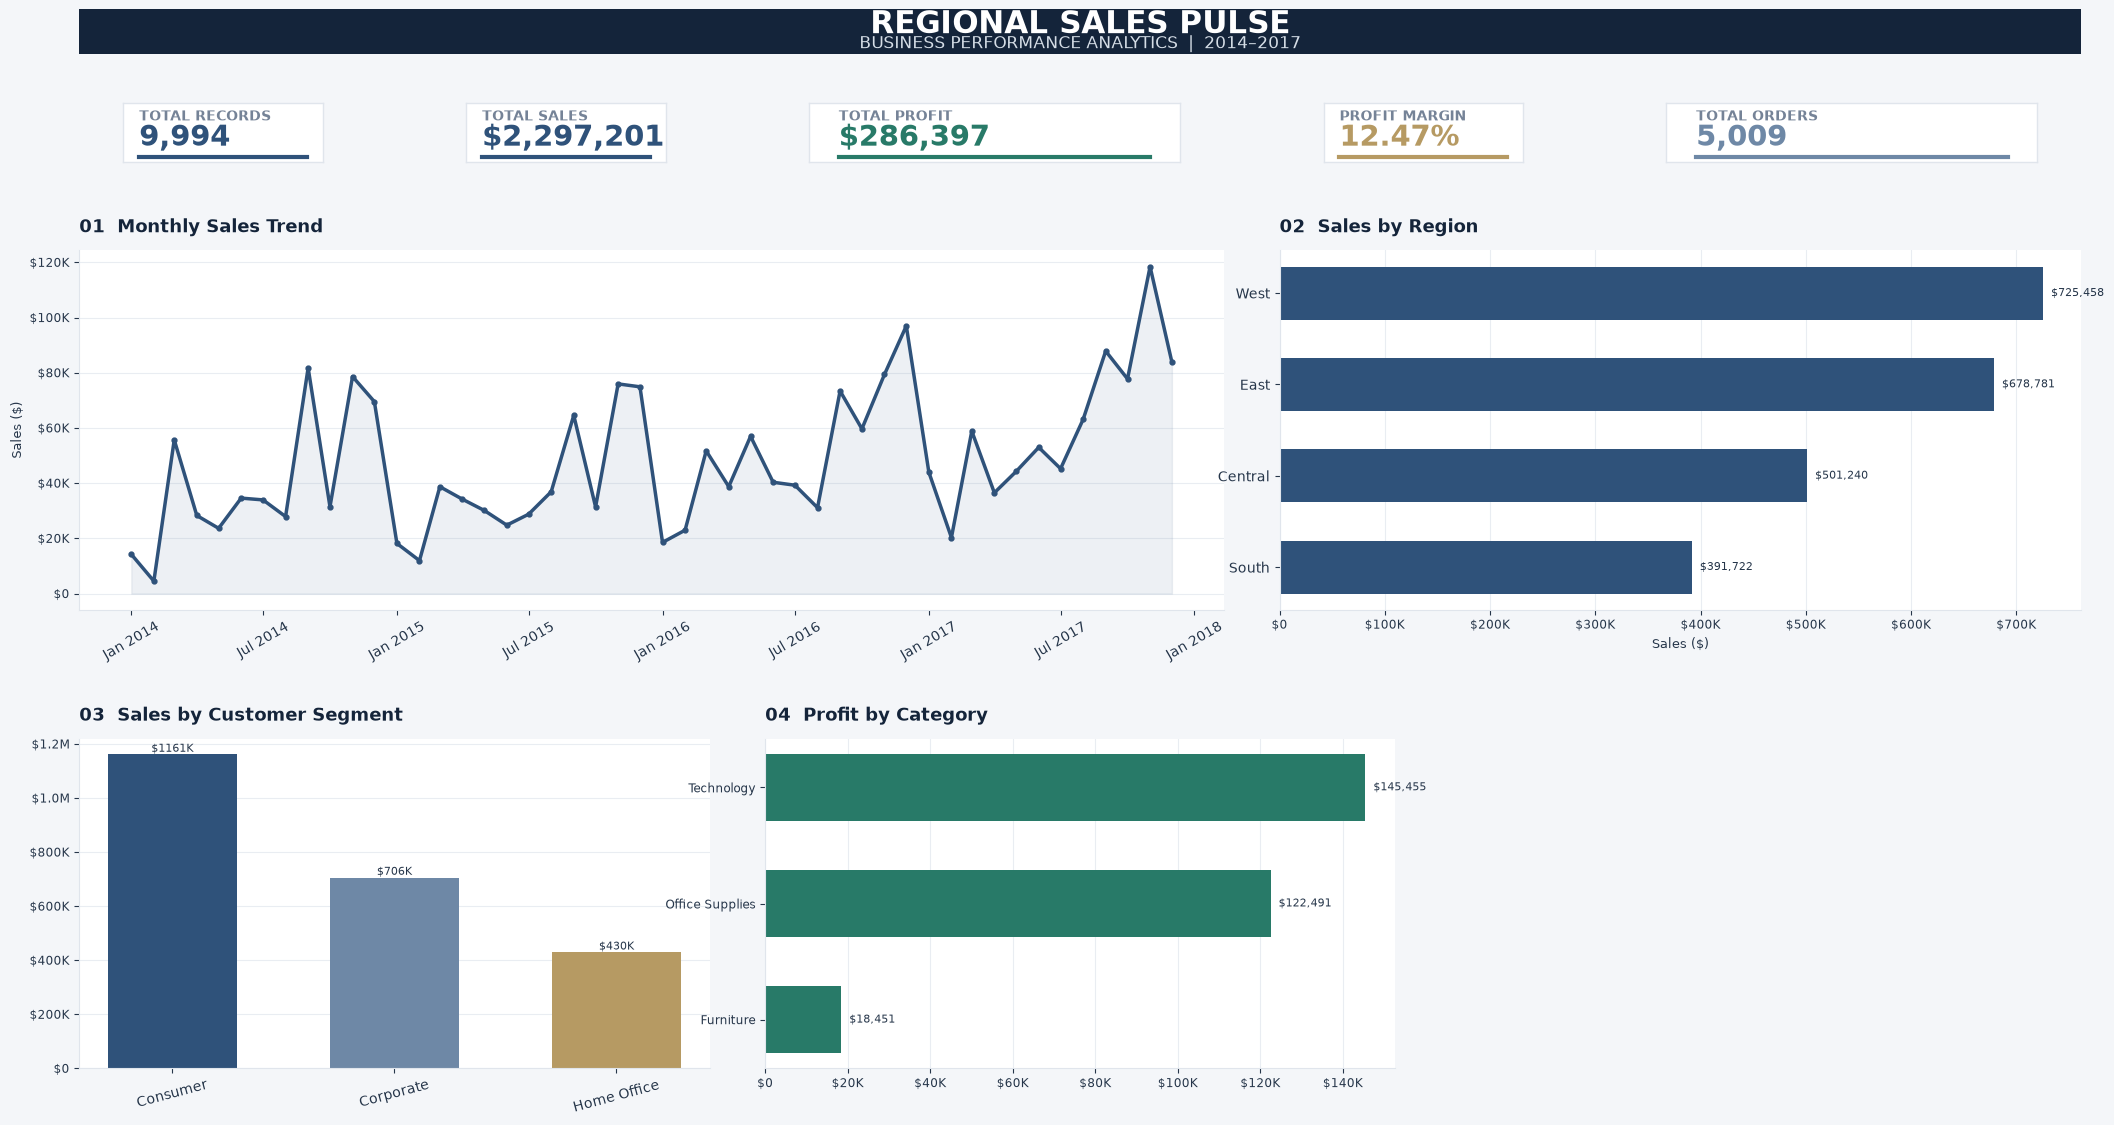

In [88]:
# ================================================================
# REGIONAL SALES PULSE
# FINAL PROFESSIONAL DATA ANALYTICS DASHBOARD
# Theme: Executive Midnight Navy & Platinum
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FuncFormatter
import warnings

warnings.filterwarnings("ignore")

# ================================================================
# 1. LOAD ORIGINAL DATASET
# ================================================================

# Load the original CSV to preserve all original records.
# Keep the original dataframe separate from chart-specific 
# # ================================================================
# REGIONAL SALES PULSE
# FINAL PROFESSIONAL DATA ANALYTICS DASHBOARD
# Theme: Executive Midnight Navy & Platinum
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FuncFormatter
import warnings

warnings.filterwarnings("ignore")

# ================================================================
# 1. LOAD ORIGINAL DATASET
# ================================================================

raw_df = pd.read_csv(
    "Sample - Superstore.csv",
    encoding="latin1"
)

df = raw_df.copy()

required_columns = [
    "Order ID", "Order Date", "Region", "Segment",
    "Category", "Sub-Category", "Sales", "Profit"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in dataset: {missing_columns}"
    )

df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

for col in ["Sales", "Profit"]:
    df[col] = pd.to_numeric(
        df[col], errors="coerce"
    )

# ================================================================
# 2. PROFESSIONAL COLOUR PALETTE
# ================================================================

BG = "#F4F6F9"
NAVY = "#14243A"
PRIMARY = "#2F527A"
STEEL = "#6E88A6"
PLATINUM = "#D5DDE6"
GOLD = "#B69A63"
GREEN = "#287A68"
RED = "#B65C62"
WHITE = "#FFFFFF"
TEXT = "#26364A"
MUTED = "#758397"
BORDER = "#E0E5EC"
GRID = "#E9EDF2"

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.titleweight"] = "bold"

# ================================================================
# 3. KPI CALCULATIONS
# ================================================================

total_records = len(raw_df)

total_orders = raw_df["Order ID"].nunique()

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

profit_margin = (
    (total_profit / total_sales) * 100
    if total_sales != 0 else 0
)

# ================================================================
# 4. FORMAT FUNCTIONS
# ================================================================

def currency_format(value):
    return f"${value:,.0f}"


def compact_currency(value, position=None):

    if abs(value) >= 1_000_000:
        return f"${value / 1_000_000:.1f}M"

    elif abs(value) >= 1_000:
        return f"${value / 1_000:.0f}K"

    return f"${value:.0f}"


# ================================================================
# 5. DATA PREPARATION
# ================================================================

# Monthly sales

monthly_data = df.dropna(
    subset=["Order Date", "Sales"]
).copy()

monthly_sales = (
    monthly_data
    .set_index("Order Date")
    .resample("MS")["Sales"]
    .sum()
)

# ================================================================
# NEXT MONTH SALES FORECAST
# METHOD: SEASONAL NAIVE
# ================================================================

if len(monthly_sales) < 12:
    raise ValueError(
        "At least 12 months of sales data is required."
    )

# Identify next month

forecast_date = (
    monthly_sales.index[-1] + pd.offsets.MonthBegin(1)
)

# Same month in the previous year

reference_date = (
    forecast_date - pd.DateOffset(years=1)
)

if reference_date not in monthly_sales.index:
    raise ValueError(
        "Previous year's corresponding month is unavailable."
    )

# Seasonal Naive forecast

forecast_sales = monthly_sales.loc[reference_date]

print("\n========== NEXT MONTH SALES FORECAST ==========")
print("Forecast Method :", "Seasonal Naive")
print("Forecast Month  :", forecast_date.strftime("%B %Y"))
print(f"Forecasted Sales: ${forecast_sales:,.2f}")


# Regional sales and profit

region = (
    df.dropna(subset=["Region", "Sales", "Profit"])
    .groupby("Region")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
)

# Customer segment

segment = (
    df.dropna(subset=["Segment", "Sales", "Profit"])
    .groupby("Segment")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
)

# Category

category = (
    df.dropna(subset=["Category", "Sales", "Profit"])
    .groupby("Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
)

# Sub-category profit

subcategory = (
    df.dropna(subset=["Sub-Category", "Profit"])
    .groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values()
)

# Sub-category sales and profit

subcategory_sales_profit = (
    df.dropna(
        subset=["Sub-Category", "Sales", "Profit"]
    )
    .groupby("Sub-Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
)

# Top 5 and Bottom 5 sub-categories

bottom_5 = subcategory.head(5)
top_5 = subcategory.tail(5)

selected_sub = pd.concat([
    bottom_5,
    top_5
])

selected_sub = selected_sub[
    ~selected_sub.index.duplicated(keep="first")
].sort_values()



# ================================================================
# 7. BUSINESS INSIGHTS
# ================================================================

best_sales_region = region["Sales"].idxmax()
best_profit_region = region["Profit"].idxmax()
best_sales_segment = segment["Sales"].idxmax()
best_category = category["Profit"].idxmax()
best_subcategory = subcategory.idxmax()
worst_subcategory = subcategory.idxmin()

region_sales_share = (
    region.loc[best_sales_region, "Sales"]
    / total_sales * 100
)

segment_sales_share = (
    segment.loc[best_sales_segment, "Sales"]
    / total_sales * 100
)

# ================================================================
# 8. DASHBOARD LAYOUT
# ================================================================

fig = plt.figure(
    figsize=(22, 16),
    facecolor=BG
)

gs = GridSpec(
    5, 12,
    figure=fig,
    height_ratios=[0.75, 0.98, 6.0, 5.5, 2.2],
    hspace=0.48,
    wspace=0.48,
    left=0.045,
    right=0.955,
    top=0.97,
    bottom=0.17
)

# ================================================================
# 9. HEADER
# ================================================================

header = fig.add_subplot(gs[0, :])
header.set_facecolor(NAVY)

header.text(
    0.5, 0.64,
    "REGIONAL SALES PULSE",
    transform=header.transAxes,
    ha="center",
    va="center",
    color=WHITE,
    fontsize=22,
    fontweight="bold"
)

header.text(
    0.5, 0.23,
    "BUSINESS PERFORMANCE ANALYTICS  |  2014–2017",
    transform=header.transAxes,
    ha="center",
    va="center",
    color=PLATINUM,
    fontsize=12
)

header.set_xticks([])
header.set_yticks([])

for spine in header.spines.values():
    spine.set_visible(False)

# ================================================================
# 10. KPI CARDS
# ================================================================

kpis = [
    ("TOTAL RECORDS", f"{total_records:,}", PRIMARY),
    ("TOTAL SALES", currency_format(total_sales), PRIMARY),
    ("TOTAL PROFIT", currency_format(total_profit), GREEN),
    ("PROFIT MARGIN", f"{profit_margin:.2f}%", GOLD),
    ("TOTAL ORDERS", f"{total_orders:,}", STEEL)
]

for i, (label, value, color) in enumerate(kpis):

    ax = fig.add_subplot(
         gs[1, i * 12 // 5:(i + 1) * 12 // 5])
    pos = ax.get_position()

    ax.set_position([
        pos.x0 +0.02, 
        pos.y0 +0.025,
        pos.width -0.04 ,
        pos.height 
    ])
    ax.set_facecolor(WHITE)

    ax.text(
        0.08, 0.70,
        label,
        transform=ax.transAxes,
        fontsize=10,
        fontweight="bold",
        color=MUTED
    )

    ax.text(
        0.08, 0.27,
        value,
        transform=ax.transAxes,
        fontsize=21,
        fontweight="bold",
        color=color
    )

    ax.axhline(
        0.08,
        color=color,
        linewidth=3,
        xmin=0.08,
        xmax=0.92
    )

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_edgecolor(BORDER)
        spine.set_linewidth(1)

# ================================================================
# 11. COMMON CHART STYLE
# ================================================================

def style_chart(ax, title):

    ax.set_facecolor(WHITE)

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        color=NAVY,
        loc="left",
        pad=13
    )

    ax.tick_params(
        axis="both",
        labelsize=8.5,
        colors=TEXT
    )

    ax.set_axisbelow(True)

    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

    for side in ["left", "bottom"]:
        ax.spines[side].set_color(BORDER)

# ================================================================
# 12. CHART 1 - MONTHLY SALES TREND
# ================================================================

ax1 = fig.add_subplot(gs[2, :7])

pos = ax1.get_position()
ax1.set_position([
    pos.x0,
    pos.y0 + 0.025,
    pos.width,
    pos.height
])
style_chart(ax1, "01  Monthly Sales Trend")
ax1.plot(
    monthly_sales.index,
    monthly_sales.values,
    color=PRIMARY,
    linewidth=2.5,
    marker="o",
    markersize=3.5
)

ax1.fill_between(
    monthly_sales.index,
    monthly_sales.values,
    color=STEEL,
    alpha=0.12
)

ax1.yaxis.set_major_formatter(
    FuncFormatter(compact_currency)
)

ax1.xaxis.set_major_locator(
    mdates.MonthLocator(interval=6)
)

ax1.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

ax1.set_ylabel(
    "Sales ($)",
    fontsize=9,
    color=TEXT
)

ax1.tick_params(axis="x",labelsize=10, rotation=30)

ax1.grid(
    axis="y",
    color=GRID,
    linewidth=0.8
)

# ================================================================
# 13. CHART 2 - SALES BY REGION
# ================================================================

ax2 = fig.add_subplot(gs[2, 7:])

pos = ax2.get_position()
ax2.set_position([
    pos.x0,
    pos.y0 + 0.025,
    pos.width,
    pos.height
])

style_chart(ax2, "02  Sales by Region")

region_sorted = region.sort_values("Sales")

bars = ax2.barh(
    region_sorted.index,
    region_sorted["Sales"],
    color=PRIMARY,
    height=0.58
)

ax2.xaxis.set_major_formatter(
    FuncFormatter(compact_currency)
)

ax2.grid(
    axis="x",
    color=GRID
)

for bar in bars:

    value = bar.get_width()

    ax2.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f"  {currency_format(value)}",
        va="center",
        fontsize=8,
        color=TEXT
    )

ax2.set_xlabel(
    "Sales ($)",
    fontsize=9,
    color=TEXT
)
ax2.tick_params(
    axis="y",
    labelsize=10
)
# ================================================================
# 14. CHART 3 - CUSTOMER SEGMENT ANALYSIS
# ================================================================

ax3 = fig.add_subplot(gs[3, :4])

style_chart(ax3, "03  Sales by Customer Segment")

segment_sorted = segment.sort_values(
    "Sales",
    ascending=False
)

segment_colors = [
    PRIMARY,
    STEEL,
    GOLD
]

bars = ax3.bar(
    segment_sorted.index,
    segment_sorted["Sales"],
    color=segment_colors[:len(segment_sorted)],
    width=0.58
)

ax3.yaxis.set_major_formatter(
    FuncFormatter(compact_currency)
)

ax3.grid(
    axis="y",
    color=GRID
)

for bar in bars:

    value = bar.get_height()

    ax3.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"${value / 1000:.0f}K",
        ha="center",
        va="bottom",
        fontsize=8,
        color=TEXT
    )

ax3.tick_params(axis="x", labelsize=10,rotation=15)

# ================================================================
# 15. CHART 4 - CATEGORY PROFITABILITY
# ================================================================

ax4 = fig.add_subplot(gs[3, 4:8])

style_chart(ax4, "04  Profit by Category")

category_sorted = category.sort_values("Profit")

category_colors = [
    GREEN if value >= 0 else RED
    for value in category_sorted["Profit"]
]

bars = ax4.barh(
    category_sorted.index,
    category_sorted["Profit"],
    color=category_colors,
    height=0.58
)

ax4.axvline(
    0,
    color=NAVY,
    linewidth=1.3
)

ax4.xaxis.set_major_formatter(
    FuncFormatter(compact_currency)
)

ax4.grid(
    axis="x",
    color=GRID
)

for bar in bars:

    value = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2

    if value >= 0:
        ax4.text(
            value, y,
            f"  {currency_format(value)}",
            ha="left",
            va="center",
            fontsize=8,
            color=TEXT
        )
    else:
        ax4.text(
            value, y,
            f"{currency_format(value)}  ",
            ha="right",
            va="center",
            fontsize=8,
            color=TEXT
        )
ax5.tick_params(
    axis="y",
    labelsize=10
)
# ================================================================
# 16. CHART 5 - SUB-CATEGORY SALES PERFORMANCE
# ================================================================

ax5 = fig.add_subplot(gs[3, 8:])

style_chart(ax5, "05  Sub-Category Sales Performance")

TOP_COLOR = "#287A68"
BOTTOM_COLOR = "#B65C62"

sub_colors = [
    TOP_COLOR if value >= 0 else BOTTOM_COLOR
    for value in selected_sub.values
]

bars = ax5.barh(
    selected_sub.index,
    selected_sub.values,
    color=sub_colors,
    height=0.68
)

ax5.axvline(
    0,
    color=NAVY,
    linewidth=1.4
)

ax5.xaxis.set_major_formatter(
    FuncFormatter(compact_currency)
)

ax5.grid(
    axis="x",
    color=GRID
)

for bar in bars:

    value = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2

    if value >= 0:
        ax5.text(
            value, y,
            f"  {currency_format(value)}",
            ha="left",
            va="center",
            fontsize=7.5,
            color=TEXT
        )
    else:
        ax5.text(
            value, y,
            f"{currency_format(value)}  ",
            ha="right",
            va="center",
            fontsize=7.5,
            color=TEXT
        )
     
ax5.tick_params(
    axis="y",
    labelsize=10,pad=3
)
# ================================================================
# 17. CHART 6 - NEXT MONTH SALES FORECAST
# ================================================================

ax6 = fig.add_subplot(gs[4, :7])
# Reduce the graph size and move it slightly downward
pos = ax6.get_position()

ax6.set_position([
    pos.x0,
    pos.y0 - 0.035,  # Move downward
    pos.width,
    pos.height * 1.4# Reduce height
])

style_chart(ax6, "06  Next Month Sales Forecast")

# Latest 12 months of historical sales

history = monthly_sales.tail(12)

ax6.plot(
    history.index,
    history.values,
    color=PRIMARY,
    linewidth=2.5,
    marker="o",
    markersize=5,
    label="Historical Sales"
)

# Forecast point connected to the latest actual sales

ax6.plot(
    [history.index[-1], forecast_date],
    [history.iloc[-1], forecast_sales],
    color=RED,
    linewidth=1.5,
    linestyle="--",
    marker="o",
    markersize=5,
    label="Next Month Forecast"
)

ax6.axvline(
    forecast_date,
    color=PLATINUM,
    linestyle=":",
    linewidth=1.5
)

ax6.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

ax6.xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

ax6.yaxis.set_major_formatter(
    FuncFormatter(compact_currency)
)

ax6.set_xlabel(
    "Month",
    fontsize=10,
    color=TEXT
)

ax6.set_ylabel(
    "Sales ($)",
    fontsize=10,
    color=TEXT
)

ax6.tick_params(axis="both",labelsize=9, rotation=30)

ax6.grid(
    axis="y",
    color=GRID,
    linewidth=0.8
)

ax6.legend(
    loc="upper left",
    frameon=False,
    fontsize=8
)

ax6.annotate(
    f"${forecast_sales:,.0f}",
    xy=(forecast_date, forecast_sales),
    xytext=(0, 12),
    textcoords="offset points",
    ha="center",
    fontsize=9,
    fontweight="bold",
    color=RED
)
ax6.tick_params(
    axis="x",
    labelsize=10
)
# ================================================================
# 18. BUSINESS INSIGHTS & RECOMMENDATIONS
# ================================================================

insight_ax = fig.add_subplot(gs[4, 6:])

# Increase the white box height
pos = insight_ax.get_position()

insight_ax.set_position([
    0.6, # left position
    0.02, # bottom position
    0.35, # box width
    0.43 # box height, enough room for five insights and five recommendations
])

insight_ax.set_facecolor(WHITE)
insight_ax.set_xticks([])
insight_ax.set_yticks([])

for spine in insight_ax.spines.values():
    spine.set_edgecolor(BORDER)
    spine.set_linewidth(1.8)

# BUSINESS INSIGHTS HEADING

insight_ax.text(
    0.05, 0.95,
    "BUSINESS INSIGHTS",
    transform=insight_ax.transAxes,
    fontsize=16,
    fontweight="bold",
    color=NAVY,
    va="top"
)

# BUSINESS INSIGHTS AND RECOMMENDATIONS
# Recalculate every finding from the full cleaned dataset.

region["Profit_Margin"] = np.where(
    region["Sales"] != 0,
    region["Profit"] / region["Sales"] * 100,
    0
)
lowest_margin_region = region["Profit_Margin"].idxmin()
highest_sales_region = region["Sales"].idxmax()
highest_profit_region = region["Profit"].idxmax()

annual_sales_dashboard = (
    df.groupby(df["Order Date"].dt.year)["Sales"].sum().sort_index()
)
annual_values_dashboard = "; ".join(
    f"{int(year)}: ${value:,.0f}"
    for year, value in annual_sales_dashboard.items()
)
annual_growth_dashboard = annual_sales_dashboard.pct_change() * 100
annual_growth_text_dashboard = ", ".join(
    f"{int(year)} {growth:+.2f}%"
    for year, growth in annual_growth_dashboard.dropna().items()
)

category_margin_dashboard = (
    category["Profit"] / category["Sales"] * 100
)
lowest_margin_category = category_margin_dashboard.idxmin()
loss_subcategories_dashboard = subcategory[subcategory < 0]
loss_names_dashboard = ", ".join(loss_subcategories_dashboard.index.tolist())

discount_corr_dashboard = df["Discount"].corr(df["Profit"])
order_discount_dashboard = (
    df.groupby(["Discount", "Order ID"], as_index=False)
    .agg(Order_Profit=("Profit", "sum"))
)
discount_order_summary_dashboard = (
    order_discount_dashboard.groupby("Discount")
    .agg(
        Average_Order_Profit=("Order_Profit", "mean"),
        Orders=("Order ID", "nunique")
    )
    .sort_index()
)
positive_20 = discount_order_summary_dashboard.loc[0.20]
negative_30 = discount_order_summary_dashboard.loc[0.30]

monthly_period_dashboard = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum().sort_index()
)
forecast_3m_dashboard = monthly_period_dashboard.shift(1).rolling(3).mean()
forecast_6m_dashboard = monthly_period_dashboard.shift(1).rolling(6).mean()
forecast_seasonal_dashboard = monthly_period_dashboard.shift(12)
forecast_eval_dashboard = pd.DataFrame({
    "Actual": monthly_period_dashboard,
    "3-Month MA": forecast_3m_dashboard,
    "6-Month MA": forecast_6m_dashboard,
    "Seasonal Naive": forecast_seasonal_dashboard
}).dropna().tail(12)

forecast_wape_dashboard = {}
for method in ["3-Month MA", "6-Month MA", "Seasonal Naive"]:
    forecast_wape_dashboard[method] = (
        (forecast_eval_dashboard["Actual"] - forecast_eval_dashboard[method]).abs().sum()
        / forecast_eval_dashboard["Actual"].abs().sum()
    ) * 100
best_method_dashboard = min(
    forecast_wape_dashboard, key=forecast_wape_dashboard.get
)

insights = [
    f"{highest_sales_region} leads regional sales (${region.loc[highest_sales_region, 'Sales']:,.2f}) and {highest_profit_region} leads regional profit (${region.loc[highest_profit_region, 'Profit']:,.2f}); {lowest_margin_region} has the lowest margin ({region.loc[lowest_margin_region, 'Profit_Margin']:.2f}%).",
    f"Annual sales: {annual_values_dashboard}. Year-on-year changes: {annual_growth_text_dashboard}.",
    f"{best_category} has the highest category profit (${category.loc[best_category, 'Profit']:,.2f}); {lowest_margin_category} has the lowest category margin ({category_margin_dashboard.loc[lowest_margin_category]:.2f}%). Loss-making sub-categories: {loss_names_dashboard}.",
    f"Discount-profit correlation is {discount_corr_dashboard:.3f}. Average order profit: 20% discount ${positive_20['Average_Order_Profit']:,.2f} ({int(positive_20['Orders']):,} orders); 30% discount ${negative_30['Average_Order_Profit']:,.2f} ({int(negative_30['Orders']):,} orders).",
    f"{best_sales_segment} leads segment sales and profit. {best_method_dashboard} is the best of the three tested forecast methods (WAPE {forecast_wape_dashboard[best_method_dashboard]:.2f}%)."
]

recommendations = [
    f"Improve {lowest_margin_region} profitability by reviewing discounting, product mix, shipping costs and loss-making products; monitor its {region.loc[lowest_margin_region, 'Profit_Margin']:.2f}% margin.",
    f"Use the annual sales pattern ({annual_growth_text_dashboard}) to guide inventory, staffing and promotions; investigate the years with declines or unusually strong growth.",
    f"Protect the contribution from {best_category}; review the pricing, costs and performance of {lowest_margin_category} and loss-making sub-categories: {loss_names_dashboard}.",
    f"Apply margin-based discount approvals. Review 30% discounts particularly carefully because average order profit was ${negative_30['Average_Order_Profit']:,.2f} across {int(negative_30['Orders']):,} orders.",
    f"Use {best_method_dashboard} as the current forecasting reference (WAPE {forecast_wape_dashboard[best_method_dashboard]:.2f}%). Compare forecasts with actuals and reassess accuracy as new monthly data arrives."
]

# BUSINESS INSIGHTS HEADING
insight_ax.text(
    0.05, 0.97,
    "BUSINESS INSIGHTS",
    transform=insight_ax.transAxes,
    fontsize=11,
    fontweight="bold",
    color=NAVY,
    va="top"
)

y = 0.87
for number, insight in enumerate(insights, start=1):
    insight_ax.text(
        0.06, y,
        f"{number}. {insight}",
        transform=insight_ax.transAxes,
        fontsize=7.2,
        color=TEXT,
        va="top",
        wrap=True
    )
    y -= 0.105

# RECOMMENDATIONS HEADING
insight_ax.text(
    0.05, 0.34,
    "BUSINESS RECOMMENDATIONS",
    transform=insight_ax.transAxes,
    fontsize=11,
    fontweight="bold",
    color=NAVY,
    va="top"
)

y = 0.25
for number, recommendation in enumerate(recommendations, start=1):
    insight_ax.text(
        0.06, y,
        f"{number}. {recommendation}",
        transform=insight_ax.transAxes,
        fontsize=7.0,
        color=TEXT,
        va="top",
        wrap=True
    )
    y -= 0.065

# ================================================================
# 19. FORECAST INTERPRETATION
# ================================================================

fig.text(
    0.27, 0.075,
    f"Best Method: Seasonal Naive  |  "
    f"Forecast Month: {forecast_date.strftime('%B %Y')}  |  "
    f"Predicted Sales: ${forecast_sales:,.2f}",
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold",
    color=NAVY
)

fig.text(
    0.27, 0.045,
    "Note: This forecast is an estimate based on the same "
    "month of the previous year.",
    ha="center",
    va="center",
    fontsize=13,
    color=TEXT
)


# ================================================================
# 20. FOOTER
# ================================================================

fig.text(
    0.5, 0.015,
    "REGIONAL SALES PULSE  |  DATA ANALYTICS PROJECT",
    ha="center",
    fontsize=8,
    color=MUTED
)

# ================================================================
# 21. EXPORT DASHBOARD
# ================================================================
# MAKE ALL GRAPH TEXT BOLD

for ax in fig.axes:

    # X-axis and Y-axis tick values
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")

    # Axis labels
    ax.xaxis.label.set_fontweight("bold")
    ax.yaxis.label.set_fontweight("bold")

    # Chart titles
    ax.title.set_fontweight("bold")

    # Bar values and other annotations
    for txt in ax.texts:
        txt.set_fontweight("bold")

    # Legend labels
    legend = ax.get_legend()
    if legend:
        for txt in legend.get_texts():
            txt.set_fontweight("bold")
plt.savefig(
    "Regional_Sales_Pulse_Final.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=BG
)

plt.savefig(
    "Regional_Sales_Pulse_Final.pdf",
    dpi=300,
    bbox_inches="tight",
    facecolor=BG
)

plt.show()

# ================================================================
# 22. DATA VERIFICATION
# ================================================================

print("\n========== DATASET VERIFICATION ==========")

print(f"Total Records       : {total_records:,}")
print(f"Unique Order IDs    : {total_orders:,}")
print(f"Total Sales         : {currency_format(total_sales)}")
print(f"Total Profit        : {currency_format(total_profit)}")
print(f"Profit Margin       : {profit_margin:.2f}%")

print("\n========== REGIONAL PERFORMANCE ==========")
print(region.sort_values("Sales", ascending=False))

print("\n========== CUSTOMER SEGMENT ==========")
print(segment.sort_values("Sales", ascending=False))

print("\n========== CATEGORY PROFITABILITY ==========")
print(category.sort_values("Profit", ascending=False))

print("\n========== SUB-CATEGORY PROFIT ==========")
print(subcategory.sort_values(ascending=False))

print("\n========== FORECAST SUMMARY ==========")
print("Forecast Method :", "Seasonal Naive")
print("Forecast Month  :", forecast_date.strftime("%B %Y"))
print(f"Forecasted Sales: ${forecast_sales:,.2f}")

print("\nDashboard exported successfully:")
print("1. Regional_Sales_Pulse_Final.png")
print("2. Regional_Sales_Pulse_Final.pdf")

# Business Insights

The following five insights are based on the supplied **Sample - Superstore.csv** dataset (9,994 records; 5,009 unique orders). Values below were recalculated from the CSV and checked against the executed analysis cells.

1. **Regional Performance:** West recorded the highest sales (**$725,457.82**) and highest profit (**$108,418.45**), with a profit margin of **14.94%**. Central had the lowest regional profit (**$39,706.36**) and lowest profit margin (**7.92%**), indicating a need to review its profitability.

2. **Sales Trend:** Annual sales were **$484,247.50** in 2014, **$470,532.51** in 2015, **$609,205.60** in 2016, and **$733,215.26** in 2017. Year-on-year sales changed by **-2.83%** in 2015, **+29.47%** in 2016, and **+20.36%** in 2017.

3. **Category and Sub-category Profitability:** Technology generated the highest category profit (**$145,454.95**). Furniture had the lowest category profit margin (**2.49%**). Tables recorded the largest sub-category loss (**-$17,725.48**), followed by Bookcases (**-$3,472.56**) and Supplies (**-$1,189.10**).

4. **Discount Impact on Profitability:** The transaction-level correlation between discount and profit was **-0.219**, showing a negative association but not proving causation. Average order profit was **$37.53** at a **20%** discount (2,407 orders) and **-$49.14** at a **30%** discount (211 orders). The 30% discount group therefore requires careful margin review.

5. **Customer Segment and Forecast Performance:** Consumer generated the highest sales (**$1,161,401.34**) and profit (**$134,119.21**). In the three-method forecast comparison, Seasonal Naive had the lowest WAPE (**25.32%**), compared with **30.75%** for the 3-Month Moving Average and **34.60%** for the 6-Month Moving Average. Its January 2018 estimate was **$43,971.37**.

# Business Recommendations

1. **Improve Central Region Profitability:** Review the Central region's discount levels, product mix, shipping costs, and loss-making products. Track its **7.92%** profit margin alongside sales and profit to measure improvement.

2. **Plan Around Sales Trends:** Use the annual sales pattern for inventory, staffing, and promotional planning. Investigate the 2015 decline (**-2.83%**) and identify what supported growth in 2016 (**+29.47%**) and 2017 (**+20.36%**).

3. **Strengthen Product Profitability:** Protect the contribution from Technology while reviewing pricing, costs, and operational performance for Furniture and the loss-making sub-categories, especially Tables, Bookcases, and Supplies.

4. **Implement Discount Control Strategies:** Apply margin-based discount approval rules. Review 30% discount promotions particularly carefully because the observed average order profit was **-$49.14** across **211 orders**. Evaluate promotions using profit as well as sales volume.

5. **Use Forecasting for Better Business Planning:** Use Seasonal Naive as the best-performing method among the three tested methods for this evaluation window. Compare forecasts with actual sales regularly and recalculate model accuracy as new monthly data becomes available. Treat the **$43,971.37** January 2018 estimate as a historical model output, not a guaranteed result.
